# 05 – Suy luận Thống kê: Kiểm định Giả thuyết có Đối chứng (Issue #11, W9)

**Khóa học:** INFO3020 – Nhập môn Khoa học Dữ liệu (CMC University)  
**Dữ liệu nguồn:** `data/processed/air_pollution_final.parquet` (trạm NCEM/VEA 556 Nguyễn Văn Cừ, Hà Nội)  
**Quy chuẩn đối chiếu:** QCVN 05:2023/BTNMT — PM₂.₅ trung bình 24 giờ = 50 µg/m³, trung bình năm = 25 µg/m³

---

## Câu hỏi của W9

Issue #8 mô tả *phân phối* PM₂.₅. Issue #11 hỏi tiếp: những khác biệt quan sát
được trong dữ liệu **có vượt quá dao động ngẫu nhiên hay không**, và nếu có thì
lớn đến mức nào. Cụ thể:

1. Nồng độ PM₂.₅ trung bình ngày có khác nhau giữa **bốn mùa** không?
2. **Ngày làm việc** và **ngày cuối tuần** có khác nhau không?
3. Vị trí phân phối trung bình ngày nằm **trên hay dưới ngưỡng QCVN 24 giờ** (50 µg/m³)?
4. Trung bình của trung bình ngày nằm **trên hay dưới ngưỡng QCVN năm** (25 µg/m³)?

## Nguyên tắc báo cáo

Mỗi kiểm định được trình bày theo **bộ bốn bắt buộc**: thống kê kiểm định + p-value
chính xác + effect size + khoảng tin cậy 95% bootstrap. Kèm theo là H₀/H₁, lý do
chọn phép kiểm, cỡ mẫu và số quan sát bị loại. **Không** có kết luận nào chỉ dựa
vào một p-value.

> **Phiên bản 2 — sửa theo review `5586524840` của PR #43.**
> Chuỗi PM₂.₅ trung bình ngày có tự tương quan mạnh (ρ₁ ≈ 0,73 ⇒ n_eff ≈ 47 trên
> 299 ngày). Vì vậy **p-value của SciPy trên dữ liệu này là lạc quan** (quá nhỏ),
> và block bootstrap cho *khoảng tin cậy* không tự động sửa được điều đó. Phiên bản
> này **dựng lại phân phối null dưới H₀** cho từng kiểm định, có kiểm soát sai
> lầm loại I bằng mô phỏng, và **thay đổi kết luận**: 2/4 kiểm định bác bỏ H₀
> (thay vì 3/4), và kiểm định mùa bị hạ xuống **thăm dò**.

## Phân biệt với các issue khác

| Nội dung | Thuộc issue | Notebook |
|---|---|---|
| Thống kê mô tả, hình dạng phân phối | #8 | `04_descriptive_stats.ipynb` |
| Hình giải thích cho báo cáo | #9 | `figures/FIG-01…07` |
| Kiểm định giả thuyết, effect size, CI | **#11** | **`05` (notebook này)** |
| Hồi quy + phân loại mất cân bằng | #12–#13 | `06`, `07` |


## 0. Thiết lập môi trường

Notebook chỉ gọi **một lần** `run_inference()` rồi tái sử dụng payload. Mọi con số
hiển thị bên dưới đọc từ payload đó — không có giá trị nào viết tay, nên chạy lại
trên dataset khác sẽ ra số khác thay vì giữ nguyên số cũ.

Hai helper định dạng `p_text` / `ci_text` được viết **cục bộ** (không import từ
`src.inference`) để cell cuối có thể đối chiếu chéo: nếu báo cáo và notebook lệch
định dạng hoặc lệch số, phép so chuỗi sẽ thất bại.


In [1]:
import sys
from pathlib import Path

import numpy as np
import pandas as pd

# ── Đường dẫn gốc repository ─────────────────────────────────────────────
REPO_ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(REPO_ROOT))

from src.flag_evidence import format_int_vi, format_number_vi  # noqa: E402
from src.inference import (  # noqa: E402
    ALPHA,
    BLOCK_LENGTH_DAYS,
    BLOCK_LENGTH_SENSITIVITY,
    DEFAULT_REPORT_PATH,
    HAC_LAG_DAILY,
    HAC_LAG_SENSITIVITY,
    INFERENCE_FIGURES,
    N_BOOTSTRAP,
    N_NULL_BOOTSTRAP,
    QCVN_2023_PM25_24H_LIMIT,
    QCVN_2023_PM25_ANNUAL_LIMIT,
    SEASON_DISPLAY_ORDER,
    SEASON_LABELS_VI,
    plot_inference_figures,
    qq_points,
    render_inference_report,
    run_inference,
)

pd.set_option("display.width", 200)
pd.set_option("display.max_columns", 40)
pd.set_option("display.max_colwidth", 100)

# ── Định dạng cục bộ — cố ý KHÔNG dùng helper của src.inference ─────────
_SUPERSCRIPT = str.maketrans("-0123456789", "⁻⁰¹²³⁴⁵⁶⁷⁸⁹")


def p_text(p: float) -> str:
    '''p-value: 4 chữ số thập phân, hoặc ký hiệu khoa học khi < 10⁻⁴.'''
    if p >= 1e-4:
        return f"{p:.4f}".replace(".", ",")
    exponent = int(np.floor(np.log10(p)))
    return f"{p / 10 ** exponent:.2f}".replace(".", ",") + "·10" + str(exponent).translate(_SUPERSCRIPT)


def _num(value: float, digits: int = 2) -> str:
    '''Số thập phân kiểu Việt Nam; dấu trừ viết bằng U+2212 như báo cáo.'''
    return f"{value:.{digits}f}".replace(".", ",").replace("-", "−")


def ci_text(ci) -> str:
    return f"[{_num(ci['ci_low'])}; {_num(ci['ci_high'])}]"


def pct(value: float, digits: int = 2) -> str:
    return f"{value * 100:.{digits}f}%".replace(".", ",")


def status_text(status: str) -> str:
    '''Nhãn trạng thái kết luận, giống hệt báo cáo.'''
    return {
        "confirmatory": "XÁC NHẬN",
        "exploratory": "THĂM DÒ (EXPLORATORY)",
        "not_confirmable": "KHÔNG XÁC NHẬN ĐƯỢC",
    }[status]


print("✓ Thiết lập môi trường hoàn tất.")
print(f"  REPO_ROOT:   {REPO_ROOT}")
print(f"  α:           {ALPHA}")
print(f"  CI bootstrap: {format_int_vi(N_BOOTSTRAP)} lặp · block {BLOCK_LENGTH_DAYS} ngày · seed 42")
print(f"  Null bootstrap (p): {format_int_vi(N_NULL_BOOTSTRAP)} lặp · block {BLOCK_LENGTH_DAYS} ngày")
print(f"  HAC lag:     {HAC_LAG_DAILY} ngày")


✓ Thiết lập môi trường hoàn tất.
  REPO_ROOT:   C:\Users\Admin\Documents\code_workspace\khdl
  α:           0.05
  CI bootstrap: 1.000 lặp · block 28 ngày · seed 42
  Null bootstrap (p): 5.000 lặp · block 28 ngày
  HAC lag:     28 ngày


### 0.1. Chạy toàn bộ suy luận một lần

`run_inference()` đọc dataset đã đóng băng, dựng panel ngày, chẩn đoán phân phối,
đo tự tương quan, chạy **bốn kiểm định xác nhận có xét phụ thuộc thời gian** + sáu
cặp hậu định + hai kiểm tra độ nhạy + mô phỏng kiểm soát sai lầm loại I. Hàm trả
về **một payload**; notebook không gọi lại lần thứ hai.


In [2]:
results = run_inference()

meta = results["meta"]
panel_info = results["panel"]
audit = panel_info["audit"]
panel = panel_info["frame"]
diagnostics = results["diagnostics"]
dependence = results["dependence"]
tests = results["tests"]
holm_table = results["holm_confirmatory"]
posthoc = results["posthoc_season"]
sensitivity = results["sensitivity"]
generalization = results["generalization"]
simulation = results["simulation"]
context = results["qcvn_context"]
n_days = panel_info["n"]

# ── Bất biến của thiết kế: nếu một trong số này sai, mọi số bên dưới vô nghĩa ──
assert ALPHA == 0.05
assert meta["alpha"] == ALPHA
assert meta["n_bootstrap"] == N_BOOTSTRAP == 1_000
assert meta["n_null_bootstrap"] == N_NULL_BOOTSTRAP == 5_000
assert meta["bootstrap_seed"] == 42
assert meta["block_length_days"] == BLOCK_LENGTH_DAYS == 28
assert meta["hac_lag_days"] == HAC_LAG_DAILY == 28
assert audit["days_kept"] == n_days
assert audit["days_kept"] + audit["days_dropped"] == audit["days_with_any_observation"]
assert len(holm_table) == 4 and set(tests) == {row["key"] for row in holm_table}
assert set(tests) == {"season_effect", "weekday_effect", "qcvn_24h", "qcvn_annual"}

print(f"✓ Payload sẵn sàng: n = {format_int_vi(n_days)} ngày, "
      f"{format_int_vi(audit['rows_hourly'])} dòng giờ.")
print(f"  SHA-256 dataset: {meta['dataset_sha256']}")
print(f"  NumPy / SciPy:   {meta['numpy_version']} / {meta['scipy_version']}")


✓ Payload sẵn sàng: n = 299 ngày, 9.044 dòng giờ.
  SHA-256 dataset: 866f39de1720c7273dc1f09c4932e508835589383820ad425c19521592586efd
  NumPy / SciPy:   2.5.3 / 1.18.1


---

## 1. Đơn vị phân tích và nhật ký lọc mẫu

### 1.1. Vì sao phân tích theo **ngày**, không theo **giờ**

Chuỗi PM₂.₅ theo giờ có tự tương quan rất mạnh: ACF bậc 1 xấp xỉ 0,94 (đo ở mục 3).
Nếu coi 9.044 dòng giờ là 9.044 quan sát độc lập thì cỡ mẫu hiệu dụng bị thổi phồng
khoảng 30 lần, và **mọi p-value trở nên vô nghĩa** — không phải vì phép kiểm sai mà
vì giả định độc lập bị vi phạm nặng.

Vì vậy đơn vị phân tích là **trung bình ngày**. Một ngày chỉ được giữ khi có
**≥ 18/24 giờ** (75% độ phủ) đo được `pm25`. Đây là **lựa chọn phân tích của dự án**,
**không phải** điều khoản của QCVN 05:2023/BTNMT — báo cáo phải nói rõ điều này để
người đọc không quy tiêu chí 18 giờ cho văn bản quy chuẩn.

### 1.2. Vì sao không dùng Train/Test split

Bốn phép kiểm dưới đây **không fit mô hình**, không chọn siêu tham số và không đánh
giá năng lực dự báo — nên không tồn tại đường rò rỉ Test → Train. Chúng chạy trên
toàn bộ giai đoạn quan sát để tận dụng cỡ mẫu, riêng kiểm định ngưỡng năm cần trọn
chu kỳ. Điểm cắt `2026-01-15 00:00+07:00` của Issue #7 **giữ nguyên** và vẫn là
điểm cắt duy nhất cho các mô hình ở Issue #12–#13.


In [3]:
audit_rows = [
    ("Dòng giờ trong dataset", format_int_vi(audit["rows_hourly"])),
    ("Giờ có `pm25`", format_int_vi(audit["hours_with_pm25"])),
    ("Giờ thiếu `pm25`", format_int_vi(audit["hours_missing_pm25"])),
    ("Số trạm", format_int_vi(audit["n_stations"])),
    ("Dải quan sát (giờ có pm25)", f"{audit['observed_first']} → {audit['observed_last']}"),
    ("Dải ngày đủ độ phủ", f"{audit['coverage_first']} → {audit['coverage_last']}"),
    ("Ngày có ≥ 1 giờ đo", format_int_vi(audit["days_with_any_observation"])),
    ("Ngày đủ 24/24 giờ", format_int_vi(audit["days_full_24h"])),
    ("Ngưỡng giờ tối thiểu/ngày", f"{audit['min_valid_hours']}/24"),
    ("Ngày được giữ (n phân tích)", format_int_vi(audit["days_kept"])),
    ("Ngày bị loại vì thiếu độ phủ", format_int_vi(audit["days_dropped"])),
    ("Ngày làm việc / cuối tuần", f"{format_int_vi(audit['weekday_days'])} / {format_int_vi(audit['weekend_days'])}"),
]
display(pd.DataFrame(audit_rows, columns=["Hạng mục", "Giá trị"]))

season_counts = pd.DataFrame(
    [(SEASON_LABELS_VI[s], audit["season_counts"][SEASON_LABELS_VI[s]]) for s in SEASON_DISPLAY_ORDER],
    columns=["Mùa", "Số ngày"],
)
print("Phân bố theo mùa (mùa khí tượng: Đông 12–2, Xuân 3–5, Hè 6–8, Thu 9–11):")
display(season_counts)

print(f"→ n = {format_int_vi(n_days)} ngày; {format_int_vi(audit['days_dropped'])} ngày bị loại.")
print(f"  Kiểm tra: {audit['days_kept']} + {audit['days_dropped']} = "
      f"{audit['days_kept'] + audit['days_dropped']} = số ngày có quan sát.")


,Hạng mục,Giá trị
0,Dòng giờ trong dataset,9.044
1,Giờ có `pm25`,7.495
2,Giờ thiếu `pm25`,1.549
3,Số trạm,1
4,Dải quan sát (giờ có pm25),2025-07-03 → 2026-07-15
5,Dải ngày đủ độ phủ,2025-07-04 → 2026-05-29
6,Ngày có ≥ 1 giờ đo,351
7,Ngày đủ 24/24 giờ,223
8,Ngưỡng giờ tối thiểu/ngày,18/24
9,Ngày được giữ (n phân tích),299


Phân bố theo mùa (mùa khí tượng: Đông 12–2, Xuân 3–5, Hè 6–8, Thu 9–11):


,Mùa,Số ngày
0,Đông,79
1,Xuân,83
2,Hè,53
3,Thu,84


→ n = 299 ngày; 52 ngày bị loại.
  Kiểm tra: 299 + 52 = 351 = số ngày có quan sát.


---

## 2. Chẩn đoán phân phối — không mặc định "chuẩn", cũng không chỉ dựa Shapiro-Wilk

### 2.1. Vì sao không được chỉ đọc một p-value chuẩn tắc

Shapiro-Wilk có **power rất cao khi n lớn**. Với n ≈ 300, chỉ cần lệch nhẹ so với
chuẩn — lệch không có ý nghĩa thực tiễn — là đủ để bác bỏ H₀ "phân phối chuẩn".
Vì vậy quyết định dùng phép kiểm phi tham số ở đây dựa trên **ba** nguồn bằng chứng:

1. **Hình dạng định lượng:** skewness và excess kurtosis (cỡ hiệu ứng, không phải p).
2. **Bản chất thang đo:** nồng độ bị chặn dưới 0, phân phối lệch phải, có đợt ô nhiễm tạo outlier.
3. **Câu hỏi nghiên cứu:** so sánh **mức nền phơi nhiễm** → trung vị/hạng phù hợp hơn trung bình số học.

Hai kiểm định chuẩn tắc (Shapiro-Wilk và D'Agostino K²) được báo cáo **cùng nhau**
và **không** dùng làm tiêu chí duy nhất.

### 2.2. H₀/H₁ của phần chẩn đoán

- **H₀:** dữ liệu trung bình ngày tuân theo phân phối chuẩn.
- **H₁:** dữ liệu không tuân theo phân phối chuẩn.

Đây chỉ là **chẩn đoán mô tả**, không thuộc family xác nhận — nên p của nó không
được hiệu chỉnh Holm và không được dùng để kết luận về khác biệt mùa/ngày.


In [4]:
diag = diagnostics
diag_rows = [
    ("n (ngày)", format_int_vi(diag["n"])),
    ("Trung bình ± SD", f"{format_number_vi(diag['mean'])} ± {format_number_vi(diag['sd'])} µg/m³"),
    ("Trung vị [IQR]", f"{format_number_vi(diag['median'])} [{format_number_vi(diag['q1'])}; {format_number_vi(diag['q3'])}] µg/m³"),
    ("Min – Max", f"{format_number_vi(diag['min'])} – {format_number_vi(diag['max'])} µg/m³"),
    ("Skewness (hiệu chỉnh mẫu)", format_number_vi(diag["skewness"], 4)),
    ("Excess kurtosis", format_number_vi(diag["excess_kurtosis"], 4)),
    ("Hình dạng (mô tả)", diag["shape"]),
    ("Shapiro-Wilk", f"W = {format_number_vi(diag['shapiro_w'], 4)} · p = {p_text(diag['shapiro_p'])}"),
    ("D'Agostino K²", f"K² = {format_number_vi(diag['dagostino_stat'], 3)} · p = {p_text(diag['dagostino_p'])}"),
    ("Số ngày ngoài ±3 SD", format_int_vi(diag["n_outliers_3sd"])),
]
display(pd.DataFrame(diag_rows, columns=["Chỉ số", "Giá trị"]))

qq = qq_points(panel["pm25_mean"])
tail = qq.iloc[-5:]
print(f"Q-Q: {format_int_vi(len(qq))} điểm. Năm điểm đuôi trên (chuẩn hoá): "
      f"{', '.join(format_number_vi(v) for v in tail['sample'])}.")
print("→ Đuôi trên tách khỏi đường 45°: dữ liệu lệch phải, không phải chuẩn.")


,Chỉ số,Giá trị
0,n (ngày),299
1,Trung bình ± SD,"43,38 ± 21,68 µg/m³"
2,Trung vị [IQR],"37,20 [28,83; 51,83] µg/m³"
3,Min – Max,"8,33 – 115,09 µg/m³"
4,Skewness (hiệu chỉnh mẫu),"1,2143"
5,Excess kurtosis,"0,9349"
6,Hình dạng (mô tả),"lệch mạnh về phía phải, đuôi dày hơn chuẩn"
7,Shapiro-Wilk,"W = 0,8873 · p = 4,59·10⁻¹⁴"
8,D'Agostino K²,"K² = 56,328 · p = 5,87·10⁻¹³"
9,Số ngày ngoài ±3 SD,2


Q-Q: 299 điểm. Năm điểm đuôi trên (chuẩn hoá): 2,76, 2,92, 2,96, 3,10, 3,31.
→ Đuôi trên tách khỏi đường 45°: dữ liệu lệch phải, không phải chuẩn.


**Đọc kết quả.** Cả Shapiro-Wilk và D'Agostino đều bác bỏ tính chuẩn, nhưng điều
quan trọng hơn là **độ lớn** của độ lệch: skewness dương đáng kể và excess kurtosis
dương cho thấy đuôi phải dày. Đó là lý do các phép kiểm so sánh dùng hạng/trung vị,
và lý do báo cáo luôn kèm CI bootstrap — CI theo lý thuyết chuẩn sẽ sai cả vị trí
lẫn độ rộng trên dữ liệu có đuôi dày.

Hình `FIG-08.png` là **hình bổ sung của Issue #11**, không thuộc bộ bảy hình ấn
phẩm `FIG-01…FIG-07` của Issue #9.


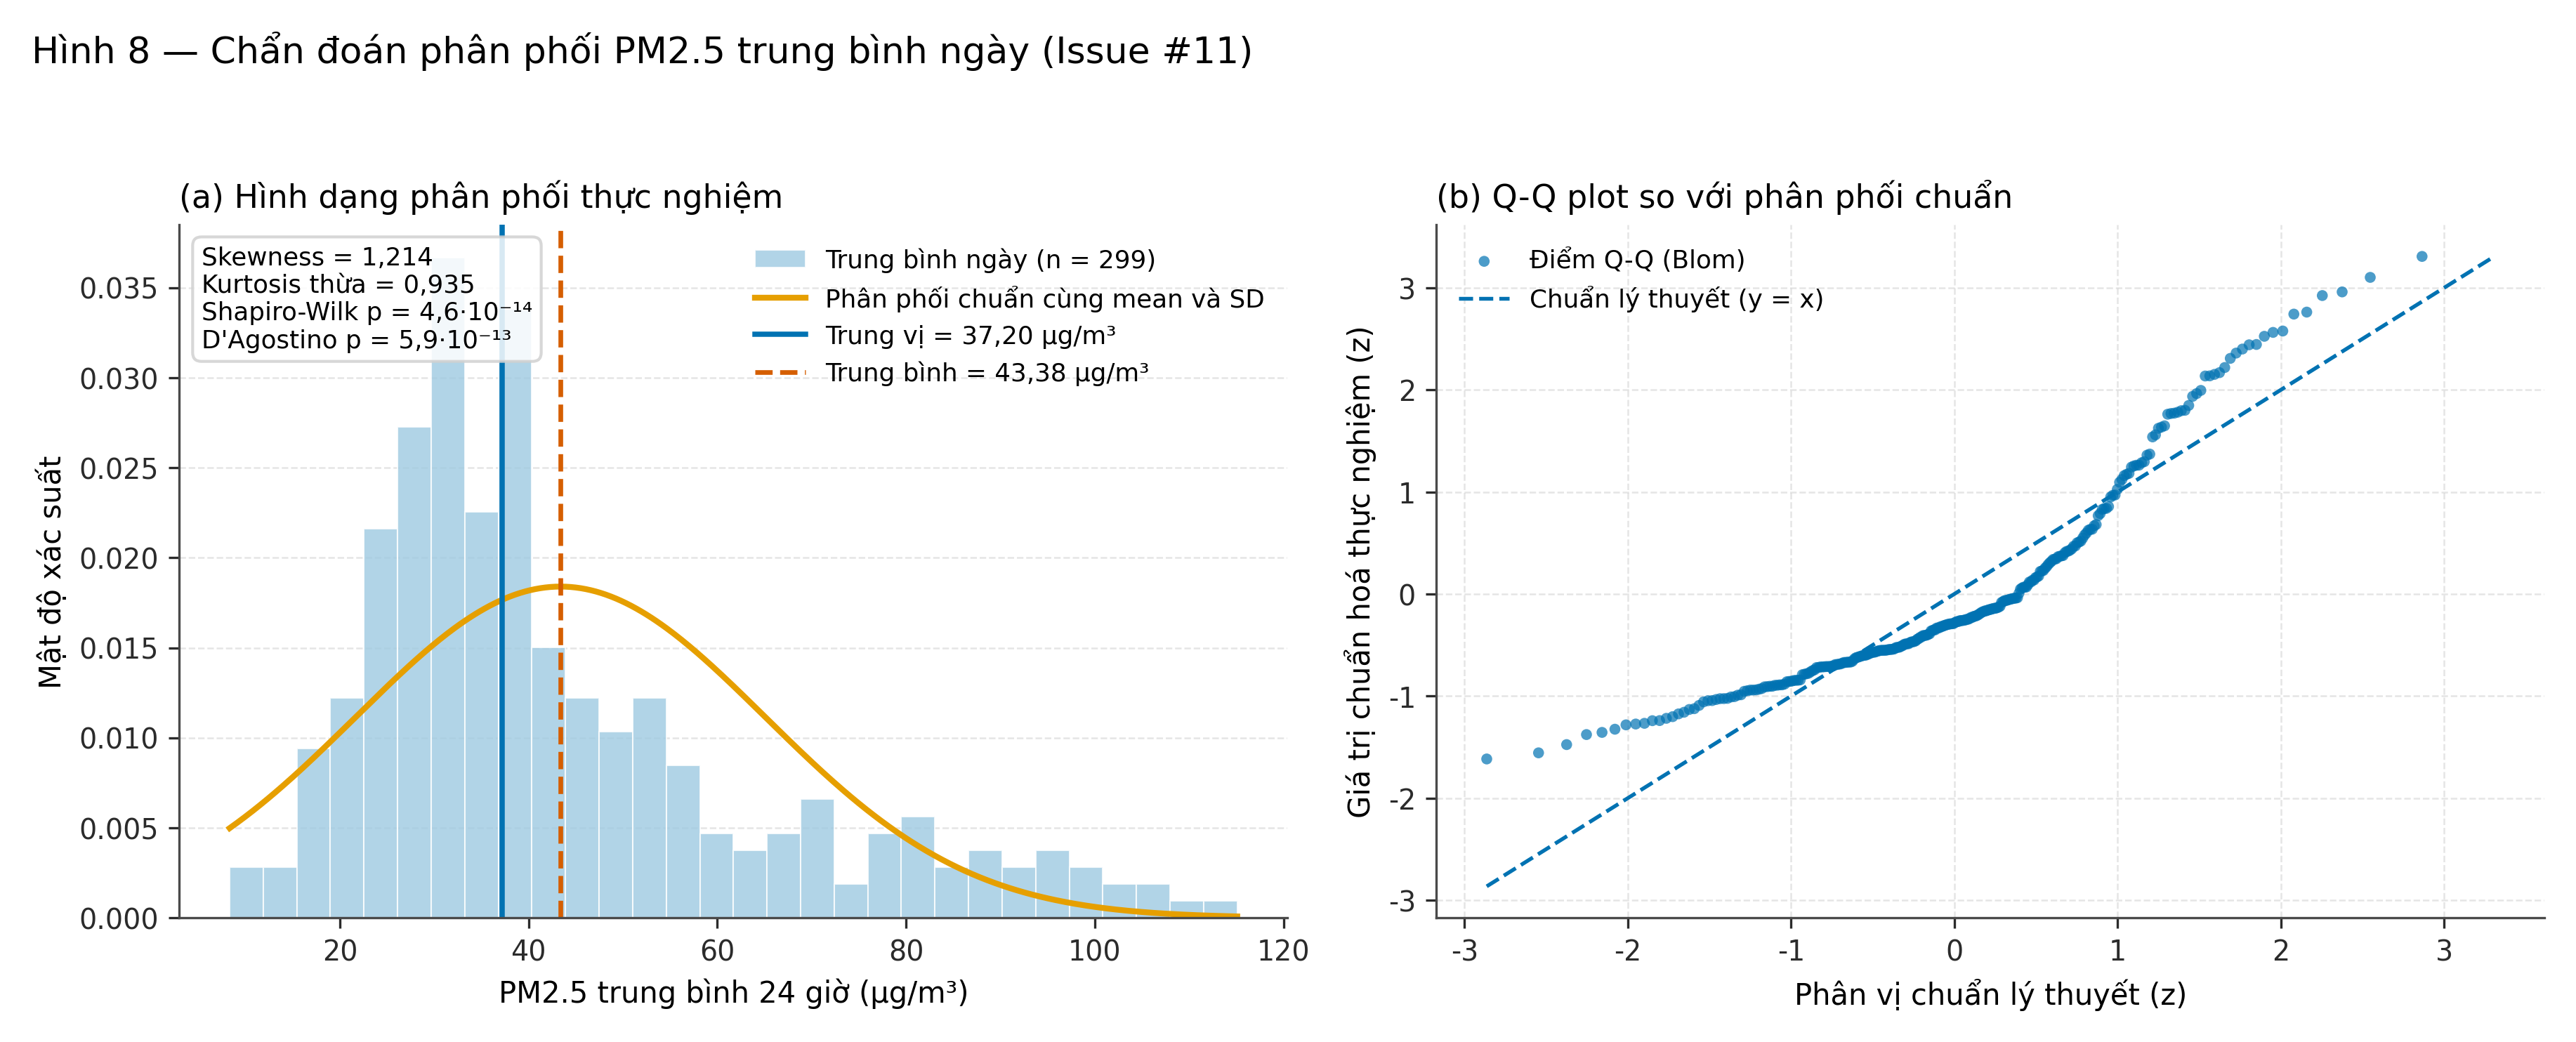

In [5]:
from IPython.display import Image, display as display_image

FIGURES = plot_inference_figures(results)
for key, filename in INFERENCE_FIGURES.items():
    path = FIGURES[key]
    assert path.exists() and path.stat().st_size > 0, path

display_image(Image(filename=str(FIGURES["distribution"]), width=760))


---

## 3. Tự tương quan và cỡ mẫu hiệu dụng — giả định nào bị vi phạm

### 3.1. Đo tự tương quan

ACF được tính trên **lưới thời gian đầy đủ**: chuỗi giờ dùng lưới giờ, chuỗi ngày
dùng lưới lịch ngày (ngày bị loại = `NaN`). Cách này quan trọng: nếu nén bỏ các
ngày thiếu rồi mới tính "lag 1", cặp giá trị đó có thể cách nhau nhiều ngày và ρ bị
chệch xuống.

### 3.2. Cỡ mẫu hiệu dụng theo xấp xỉ AR(1)

$$\hat{n}_{\text{eff}} = n \cdot \frac{1 - \hat{\rho}_1}{1 + \hat{\rho}_1}$$

Đây là **chỉ báo bậc độ lớn**, không phải hiệu chỉnh p-value. Nó trả lời: "299 ngày
này chứa bao nhiêu thông tin độc lập?" Nếu $n_{\text{eff}}$ nhỏ hơn n nhiều so với
$n$, p-value của các phép kiểm giả định độc lập là **lạc quan**.

### 3.3. Cách xử lý (sau review 5586524840)

1. Hạ đơn vị phân tích từ **giờ** xuống **ngày**.
2. **Dựng lại phân phối null dưới H₀** cho từng kiểm định — đây mới là phần sửa
   p-value (mục 4). Ở phiên bản trước, block bootstrap chỉ sửa *khoảng tin cậy*.
3. Mọi CI và mọi resample dùng **circular moving block bootstrap**, block **28 ngày**
   (4 chu kỳ tuần), **1.000 lặp** CI / **5.000 lặp** null, seed **42**, CI percentile 95%.
4. Kiểm soát sai lầm loại I bằng **mô phỏng dưới H₀** (mục 9).
5. Thêm hai **kiểm tra độ nhạy ở mức tuần** (mục 11) — nơi tự tương quan thấp hơn.


In [6]:
acf_rows = []
for lag, value in dependence["daily_acf"].items():
    acf_rows.append(("Ngày", f"lag {lag}", format_number_vi(value, 4)))
for lag, value in dependence["hourly_acf"].items():
    acf_rows.append(("Giờ", f"lag {lag}", format_number_vi(value, 4)))
display(pd.DataFrame(acf_rows, columns=["Chuỗi", "Bậc", "ACF"]))

eff = dependence["daily_effective_n"]
print(dependence["daily_series_note"])
print(f"AR(1) chuỗi ngày: ρ = {format_number_vi(eff['rho_lag1'], 4)} → "
      f"n_eff ≈ {format_number_vi(eff['n_effective'], 1)} so với n = {format_int_vi(eff['n'])} "
      f"(lạm phát ×{format_number_vi(eff['inflation_factor'], 2)}).")

assert eff["n_effective"] < eff["n"], "n_eff phải nhỏ hơn n khi ρ > 0"
assert dependence["hourly_acf"][1] > dependence["daily_acf"][1], "ACF giờ phải cao hơn ACF ngày"


,Chuỗi,Bậc,ACF
0,Ngày,lag 1,"0,7276"
1,Ngày,lag 2,"0,5484"
2,Ngày,lag 3,"0,4239"
3,Ngày,lag 7,"0,3700"
4,Ngày,lag 14,"0,3172"
5,Giờ,lag 1,"0,9403"
6,Giờ,lag 2,"0,8371"
7,Giờ,lag 3,"0,7432"
8,Giờ,lag 24,"0,5988"
9,Giờ,lag 168,"0,3449"


ACF ngày tính trên lưới lịch đầy đủ (ngày bị loại = NaN), không nén bỏ khoảng trống.
AR(1) chuỗi ngày: ρ = 0,7276 → n_eff ≈ 47,1 so với n = 299 (lạm phát ×6,34).


**Hệ quả — nói thẳng, không che.** Mann-Whitney, Kruskal-Wallis, Wilcoxon và
t-test đều giả định quan sát độc lập. Ở mức ngày, giả định đó **không** được bảo
đảm ($\hat{\rho}_1 \approx 0{,}73$). Vì vậy:

- p-value của SciPy trên dữ liệu này là **lạc quan** — mức lạc quan được đo bằng
  mô phỏng ở mục 9 (tỷ lệ bác bỏ dưới H₀ lên tới 80% so với α = 5%).
- Mọi kết luận phải đọc kèm effect size và CI.
- Block bootstrap chỉ sửa **khoảng tin cậy** nếu ta dùng nó cho CI; muốn sửa
  **p-value** thì phải dựng phân phối null dưới H₀ — đó là mục 4.


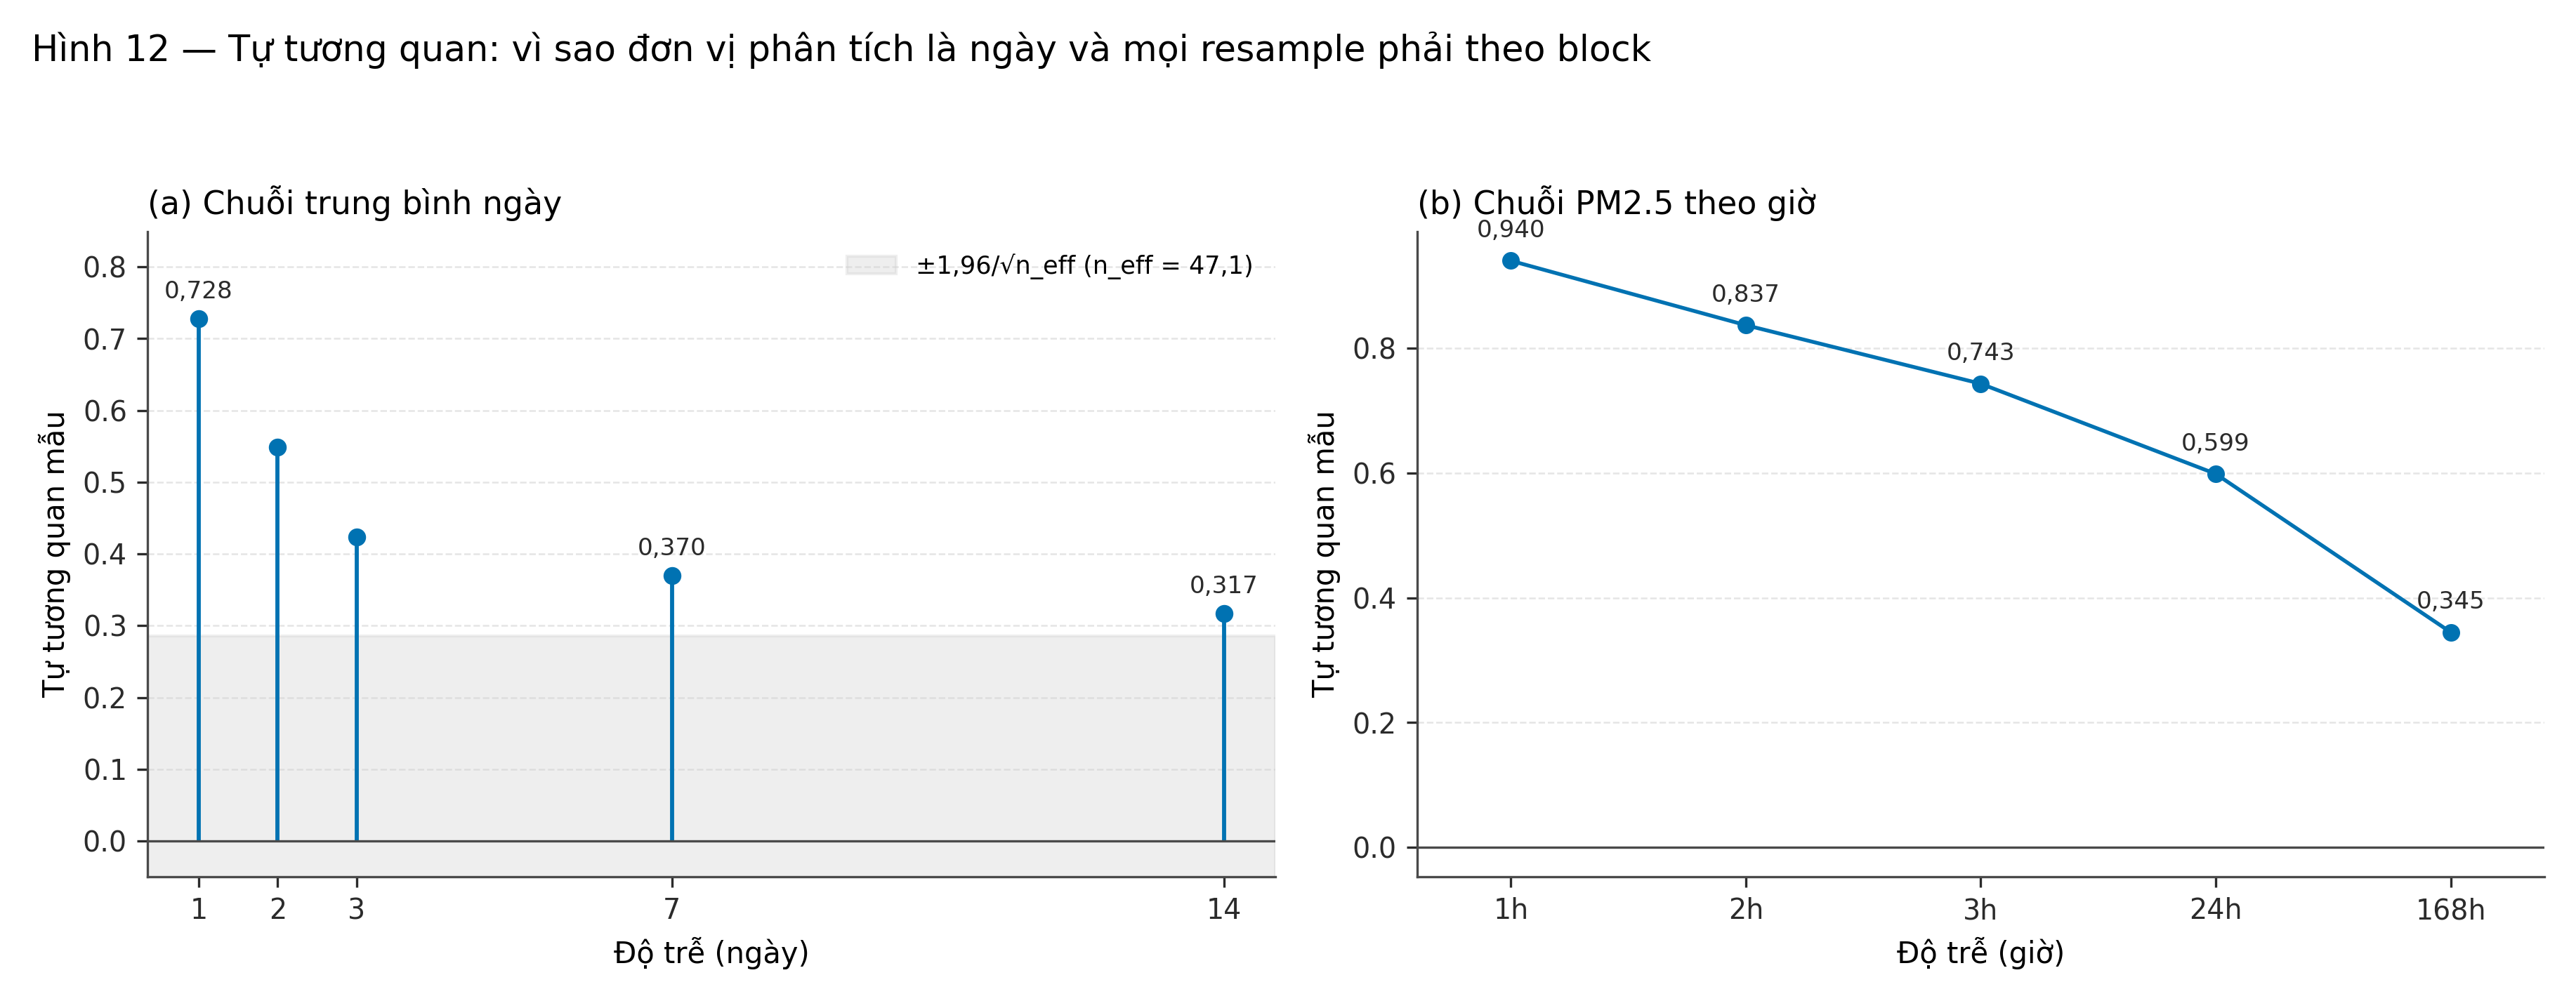

In [7]:
display_image(Image(filename=str(FIGURES["autocorrelation"]), width=760))


---

## 4. Khung phương pháp: dựng phân phối null dưới H₀ có xét phụ thuộc thời gian

### 4.1. Bốn giả thuyết — phát biểu trước khi xem kết quả

| # | Câu hỏi | H₀ | H₁ | Phương pháp **chính** | Vì sao phương pháp này |
|---|---|---|---|---|---|
| 1 | Khác biệt giữa bốn mùa | 4 mùa cùng phân phối (quá trình ổn định) | Có ít nhất một mùa khác | Kruskal-Wallis + **null block bootstrap** trên chuỗi gộp | Omnibus 4 nhóm; null được dựng dưới H₀ với cấu trúc phụ thuộc được giữ |
| 2 | Ngày làm việc vs cuối tuần | Hai nhóm cùng phân phối | Hai nhóm khác nhau | Mann-Whitney U + **null block bootstrap** trên chuỗi gộp | So hạng, bền với outlier; null dựng dưới H₀ |
| 3 | QCVN 24 giờ (50 µg/m³) | P(trung bình ngày > 50) = 0,5 | Khác 0,5 | **HAC/Newey–West** cho tỷ lệ vượt ngưỡng | Tương đương trung vị = 50 với phân phối liên tục; SE sandwich xử lý tự tương quan |
| 4 | QCVN năm (25 µg/m³) | E(trung bình ngày) = 25 | Khác 25 | **HAC/Newey–West** (mô hình chỉ có hệ số chặn) | Ngưỡng năm là ngưỡng của **trung bình**; SE sandwich là phương sai dài hạn |

**Cả bốn kiểm định đều hai phía, α = 0,05.** Chiều của hiệu ứng **không** được suy
từ p-value mà đọc từ ước lượng điểm và CI. Lý do: chọn một phía sau khi nhìn dữ
liệu là thay đổi giả thuyết giữa chừng — làm p mất ý nghĩa.

### 4.2. Ba nguyên tắc bắt buộc của phương pháp

1. **Null phải được dựng DƯỚI H₀.** Với kiểm định theo nhóm, null là chuỗi **gộp**
   (H₀: các nhóm cùng phân phối). Với kiểm định vị trí, H₀ được **áp đặt** bằng
   cách dựng bản sao `x* = μ + resample(x − θ̂)` — mốc của H₀ nằm trong bản sao.
   **Không** dùng bootstrap trên chuỗi quan sát rồi đếm tỷ lệ thống kê cực đoan.
2. **Nhãn nhóm đi theo vị trí lịch, không hoán đổi ngẫu nhiên.** Hoán đổi nhãn mùa
   sẽ phá vỡ cấu trúc mùa vụ (mùa là các **đoạn thời gian liên tiếp**).
3. **CI ≠ p-value.** CI là khoảng tin cậy của ước lượng; p-value là xác suất của dữ
   liệu **có điều kiện H₀ đúng**. Báo cáo in cả hai, không suy ra cái này từ cái kia.

### 4.3. Quy tắc hạ mức kết luận — chốt trước khi xem kết quả

| Quy tắc | Điều kiện | Hệ quả |
|---|---|---|
| R1 — Ổn định | Kết luận đổi chiều khi đổi độ dài block / lag HAC trong lưới độ nhạy | Hạ xuống **THĂM DÒ** |
| R2 — Đồng thuận | Phương pháp đối chứng cho kết luận khác chiều phương pháp chính | Hạ xuống **THĂM DÒ** |
| R3 — Tính được | Không dựng được p hợp lệ | **KHÔNG XÁC NHẬN ĐƯỢC** |

> **Family Holm vẫn gồm đúng 4 kiểm định** như đã chốt trước khi xem dữ liệu. Việc một
> kiểm định bị hạ xuống *thăm dò* **không** làm thay đổi family — thay đổi family sau khi
> nhìn kết quả là p-hacking.

### 4.4. Vì sao Holm, và family gồm những gì

Holm kiểm soát FWER **không cần giả định các kiểm định độc lập** và luôn mạnh hơn
hoặc bằng Bonferroni. Sáu cặp mùa hậu định **không** thuộc family này: chúng được
khảo sát sau khi kiểm định omnibus, nên mang nhãn **exploratory** và được hiệu chỉnh
Holm trong **family riêng**. Hai kiểm tra độ nhạy không nằm trong family nào.


In [8]:
design_rows = []
for row in holm_table:
    test = tests[row["key"]]
    if row["key"] == "season_effect":
        n_text = f"n = {format_int_vi(test['n'])} ngày / 4 nhóm"
    elif row["key"] == "weekday_effect":
        n_text = f"n₁ = {format_int_vi(test['n_a'])}, n₂ = {format_int_vi(test['n_b'])}"
    else:
        n_text = f"n = {format_int_vi(test['n'])} ngày"
    design_rows.append((
        row["label"],
        n_text,
        test["alternative"],
        test["statistic_name"],
        test["method"]["primary"],
    ))

display(pd.DataFrame(
    design_rows,
    columns=["Kiểm định", "Cỡ mẫu", "Alternative", "Thống kê", "Phương pháp chính"],
))
print(f"→ Tổng số quan sát bị loại khỏi panel: {format_int_vi(audit['days_dropped'])} ngày "
      f"(từ {format_int_vi(audit['days_with_any_observation'])} ngày có quan sát).")
print(f"→ Block bootstrap: {format_int_vi(N_BOOTSTRAP)} lặp cho CI, "
      f"{format_int_vi(N_NULL_BOOTSTRAP)} lặp cho null p-value, block {BLOCK_LENGTH_DAYS} ngày, seed 42.")


,Kiểm định,Cỡ mẫu,Alternative,Thống kê,Phương pháp chính
0,"Mùa (4 nhóm, có xét phụ thuộc thời gian)",n = 299 ngày / 4 nhóm,omnibus (đuôi trên của H),H,Kruskal-Wallis + null circular moving block bootstrap (chuỗi gộp)
1,Ngày làm việc vs cuối tuần (có xét phụ thuộc thời gian),"n₁ = 213, n₂ = 86",hai phía,U,Mann-Whitney U + null circular moving block bootstrap (chuỗi gộp)
2,Trung bình 24h vs 50 µg/m³ (có xét phụ thuộc thời gian),n = 299 ngày,hai phía,"t (share, HAC)","H₀ 'trung vị = μ' tương đương 'P(trung bình ngày > μ) = 0,5' với phân phối liên tục; thống kê là..."
3,Trung bình giai đoạn vs 25 µg/m³ (có xét phụ thuộc thời gian),n = 299 ngày,hai phía,t (HAC),"t-test một mẫu với sai số chuẩn HAC: mô hình chỉ có hệ số chặn, SE là ước lượng sandwich của phư..."


→ Tổng số quan sát bị loại khỏi panel: 52 ngày (từ 351 ngày có quan sát).
→ Block bootstrap: 1.000 lặp cho CI, 5.000 lặp cho null p-value, block 28 ngày, seed 42.


---

## 5. Family xác nhận — p thô, p Holm và trạng thái kết luận

Cột **p thô** được giữ nguyên để người đọc tự kiểm tra: hiệu chỉnh Holm có làm đổi
kết luận hay không. Bảng còn in **p tham chiếu** — p-value của phép kiểm SciPy cũ
(giả định quan sát độc lập) — để thấy rõ hiệu chỉnh phụ thuộc thời gian đã làm thay
đổi kết luận thế nào.


In [9]:
holm_rows = []
for row in holm_table:
    holm_rows.append({
        "Kiểm định": row["label"],
        "Thống kê": f"{row['statistic_name']} = {format_number_vi(row['statistic'], 4)}",
        "p (hiệu chỉnh)": p_text(row["p_raw"]),
        "p Holm": p_text(row["p_holm"]),
        "p tham chiếu": p_text(row["p_raw_independence"]),
        "Effect size": f"{row['effect_size_name']} = {format_number_vi(row['effect_size'], 4)}",
        "Trạng thái": status_text(row["status"]),
    })
display(pd.DataFrame(holm_rows))

for row in holm_table:
    assert row["p_holm"] >= row["p_raw"] - 1e-12, "Holm không được làm p nhỏ đi"
    assert row["reject_holm"] == (row["p_holm"] < ALPHA)
    assert row["reject_raw"] == (row["p_raw"] < ALPHA)

n_reject = sum(row["reject_holm"] for row in holm_table)
n_reject_ref = sum(row["reject_holm_independence"] for row in holm_table)
n_expl = sum(row["status"] == "exploratory" for row in holm_table)
print(f"→ Có xét phụ thuộc thời gian: {n_reject}/4 bác bỏ H₀ sau Holm "
      f"({n_expl} kiểm định ở trạng thái thăm dò).")
print(f"→ Tham chiếu (giả định độc lập): {n_reject_ref}/4 bác bỏ H₀ sau Holm.")
print("→ Family giữ nguyên 4 kiểm định như đã chốt trước khi xem dữ liệu.")


,Kiểm định,Thống kê,p (hiệu chỉnh),p Holm,p tham chiếu,Effect size,Trạng thái
0,"Mùa (4 nhóm, có xét phụ thuộc thời gian)","H = 61,5344","0,0444","0,0888","2,76·10⁻¹³","epsilon_squared = 0,2065",THĂM DÒ (EXPLORATORY)
1,Ngày làm việc vs cuối tuần (có xét phụ thuộc thời gian),"U = 8083,0000","0,0780","0,0888","0,1120","r_rb = −0,1175",XÁC NHẬN
2,Trung bình 24h vs 50 µg/m³ (có xét phụ thuộc thời gian),"t (share, HAC) = −2,6558","0,0083","0,0250","7,88·10⁻¹⁰","r_rb_pairs = −0,4102",XÁC NHẬN
3,Trung bình giai đoạn vs 25 µg/m³ (có xét phụ thuộc thời gian),"t (HAC) = 4,3535","1,84·10⁻⁵","7,38·10⁻⁵","5,33·10⁻³⁷","cohen_d = 0,8476",XÁC NHẬN


→ Có xét phụ thuộc thời gian: 2/4 bác bỏ H₀ sau Holm (1 kiểm định ở trạng thái thăm dò).
→ Tham chiếu (giả định độc lập): 3/4 bác bỏ H₀ sau Holm.
→ Family giữ nguyên 4 kiểm định như đã chốt trước khi xem dữ liệu.


---

## 6. Kiểm định 1 — Khác biệt giữa bốn mùa

- **H₀:** phân phối trung bình ngày giống nhau ở cả bốn mùa (trong một quá trình ổn định).
- **H₁:** có ít nhất một mùa khác.
- **α = 0,05**, omnibus (đuôi trên của H).

### 6.1. Phương pháp

- **Chính:** Kruskal-Wallis với **null circular moving block bootstrap** trên chuỗi
  **gộp** toàn bộ ngày; **nhãn mùa giữ theo vị trí lịch** (không hoán đổi nhãn).
- **Đối chứng:** hồi quy **HAC/Newey–West** `[1, xu hướng, 3 dummy mùa]`, kiểm định
  Wald đồng thời — dùng để **tách mùa khỏi xu hướng thời gian**, vì bốn mùa là bốn
  **đoạn thời gian liên tiếp**.

### 6.2. Vì sao mùa được định nghĩa theo khí tượng

Đông = 12–2, Xuân = 3–5, Hè = 6–8, Thu = 9–11. Định nghĩa này cố định trong
`src/flag_evidence.py` và dùng chung với Issue #8, nên nhãn mùa của hai notebook
không thể lệch nhau.


In [10]:
season = tests["season_effect"]
season_rows = [
    (SEASON_LABELS_VI[s], format_int_vi(season["group_sizes"][s]), format_number_vi(season["group_medians"][s]))
    for s in SEASON_DISPLAY_ORDER if s in season["group_sizes"]
]
display(pd.DataFrame(season_rows, columns=["Mùa", "n (ngày)", "Trung vị (µg/m³)"]))

season_ci = season["ci_dong_vs_he"]
print(f"H = {format_number_vi(season['statistic'], 4)} · df = {season['df']} · "
      f"n = {format_int_vi(season['n'])}")
print(f"p (null bootstrap, có xét phụ thuộc) = {p_text(season['p_value'])}")
print(f"p Holm                             = {p_text(season['p_holm'])}")
print(f"p tham chiếu (giả định độc lập)    = {p_text(season['p_value_independence'])}")
print(f"ε²                                 = {format_number_vi(season['effect_size'], 4)}")
print(f"Đối chứng HAC (có xu hướng): F = {format_number_vi(season['supporting_result']['statistic'], 3)}, "
      f"p = {p_text(season['supporting_result']['p_value'])}, "
      f"xu hướng = {format_number_vi(season['supporting_result']['trend_per_month'])} µg/m³ mỗi tháng")
print(f"CI 95% block bootstrap cho trung vị Đông − Hè: "
      f"{format_number_vi(season_ci['point'])} µg/m³, {ci_text(season_ci)}")

print("\nĐộ nhạy theo độ dài block (phương pháp chính):")
for name, entry in sorted(season["sensitivity"]["block_length"].items(), key=lambda kv: int(kv[0])):
    print(f"  block {name:>2} ngày: p = {p_text(entry['p_value'])}")
print("Độ nhạy theo lag HAC (phương pháp đối chứng):")
for name, entry in sorted(season["sensitivity"]["hac_lag"].items(), key=lambda kv: int(kv[0])):
    print(f"  lag {name:>2} ngày: p = {p_text(entry['p_value'])}")

print(f"\nTrạng thái kết luận: {status_text(season['status'])} — {season['status_reason']}")
assert season["status"] == "exploratory", "Kết luận mùa phải ở trạng thái thăm dò"
assert 0.0 <= season["effect_size"] <= 1.0


,Mùa,n (ngày),Trung vị (µg/m³)
0,Đông,79,"60,46"
1,Xuân,83,"32,81"
2,Hè,53,"31,14"
3,Thu,84,"36,30"


H = 61,5344 · df = 3 · n = 299
p (null bootstrap, có xét phụ thuộc) = 0,0444
p Holm                             = 0,0888
p tham chiếu (giả định độc lập)    = 2,76·10⁻¹³
ε²                                 = 0,2065
Đối chứng HAC (có xu hướng): F = 17,265, p = 2,36·10⁻¹⁰, xu hướng = −2,29 µg/m³ mỗi tháng
CI 95% block bootstrap cho trung vị Đông − Hè: 29,32 µg/m³, [9,95; 38,65]

Độ nhạy theo độ dài block (phương pháp chính):
  block  7 ngày: p = 0,0004
  block 14 ngày: p = 0,0064
  block 21 ngày: p = 0,0186
  block 28 ngày: p = 0,0444
  block 42 ngày: p = 0,0788
Độ nhạy theo lag HAC (phương pháp đối chứng):
  lag  7 ngày: p = 3,02·10⁻⁷
  lag 14 ngày: p = 5,26·10⁻⁸
  lag 21 ngày: p = 4,52·10⁻⁹
  lag 28 ngày: p = 2,36·10⁻¹⁰
  lag 42 ngày: p = 3,71·10⁻¹⁰

Trạng thái kết luận: THĂM DÒ (EXPLORATORY) — Kết luận không ổn định theo độ dài block / lag HAC → hạ xuống thăm dò.


**Đọc kết quả.** Khác biệt mùa **rõ rệt về mặt mô tả**: ε² ở mức trung bình,
CI của chênh lệch Đông − Hè không chứa 0. Nhưng p-value sau hiệu chỉnh phụ thuộc
thời gian **không ổn định** theo độ dài block (0,0004 ở block 7 ngày → 0,0788 ở block
42 ngày) — nên theo quy tắc R1 kiểm định này bị hạ xuống **THĂM DÒ**. Kết luận mùa
chỉ nên đọc như **mô tả của giai đoạn 07/2025–07/2026**, không phải quy luật nhiều
năm (mục 10).

### 6.3. Hậu định sáu cặp mùa — exploratory, Holm family riêng

Sáu cặp dưới đây **không** tham gia family xác nhận. Chúng chỉ định vị khác biệt
nằm ở đâu; p-value của chúng cũng đã được dựng lại dưới H₀ có xét phụ thuộc.


In [11]:
pair_rows = []
for pair in posthoc["pairs"]:
    pair_rows.append({
        "Cặp": pair["pair"],
        "Trung vị A": format_number_vi(pair["median_a"]),
        "Trung vị B": format_number_vi(pair["median_b"]),
        "U": format_number_vi(pair["statistic"], 1),
        "p (hiệu chỉnh)": p_text(pair["p_value"]),
        "p Holm": p_text(pair["p_holm"]),
        "p tham chiếu": p_text(pair["p_value_independence"]),
        "r_rb": format_number_vi(pair["effect_size"], 3),
        "CI 95% (A−B)": ci_text(pair["ci"]),
    })
display(pd.DataFrame(pair_rows))
assert posthoc["n_pairs"] == 6
assert all(p["p_holm"] >= p["p_value"] - 1e-12 for p in posthoc["pairs"])
print("→ Family hậu định: 6 cặp, Holm riêng, nhãn exploratory.")


,Cặp,Trung vị A,Trung vị B,U,p (hiệu chỉnh),p Holm,p tham chiếu,r_rb,CI 95% (A−B)
0,Đông – Xuân,"60,46","32,81","5191,0","0,0144","0,0720","1,49·10⁻¹⁰","0,583","[8,82; 36,68]"
1,Đông – Hè,"60,46","31,14","3519,0","0,0120","0,0720","3,72·10⁻¹¹","0,681","[9,95; 38,65]"
2,Đông – Thu,"60,46","36,30","4951,0","0,0624","0,2496","5,93·10⁻⁸","0,492","[5,31; 33,82]"
3,Xuân – Hè,"32,81","31,14","2512,0","0,6543","1,0000","0,1639","0,142","[−4,31; 7,81]"
4,Xuân – Thu,"32,81","36,30","3140,0","0,6887","1,0000","0,2688","−0,099","[−8,65; 3,55]"
5,Hè – Thu,"31,14","36,30","1731,0","0,4471","1,0000","0,0289","−0,222","[−9,59; 0,50]"


→ Family hậu định: 6 cặp, Holm riêng, nhãn exploratory.


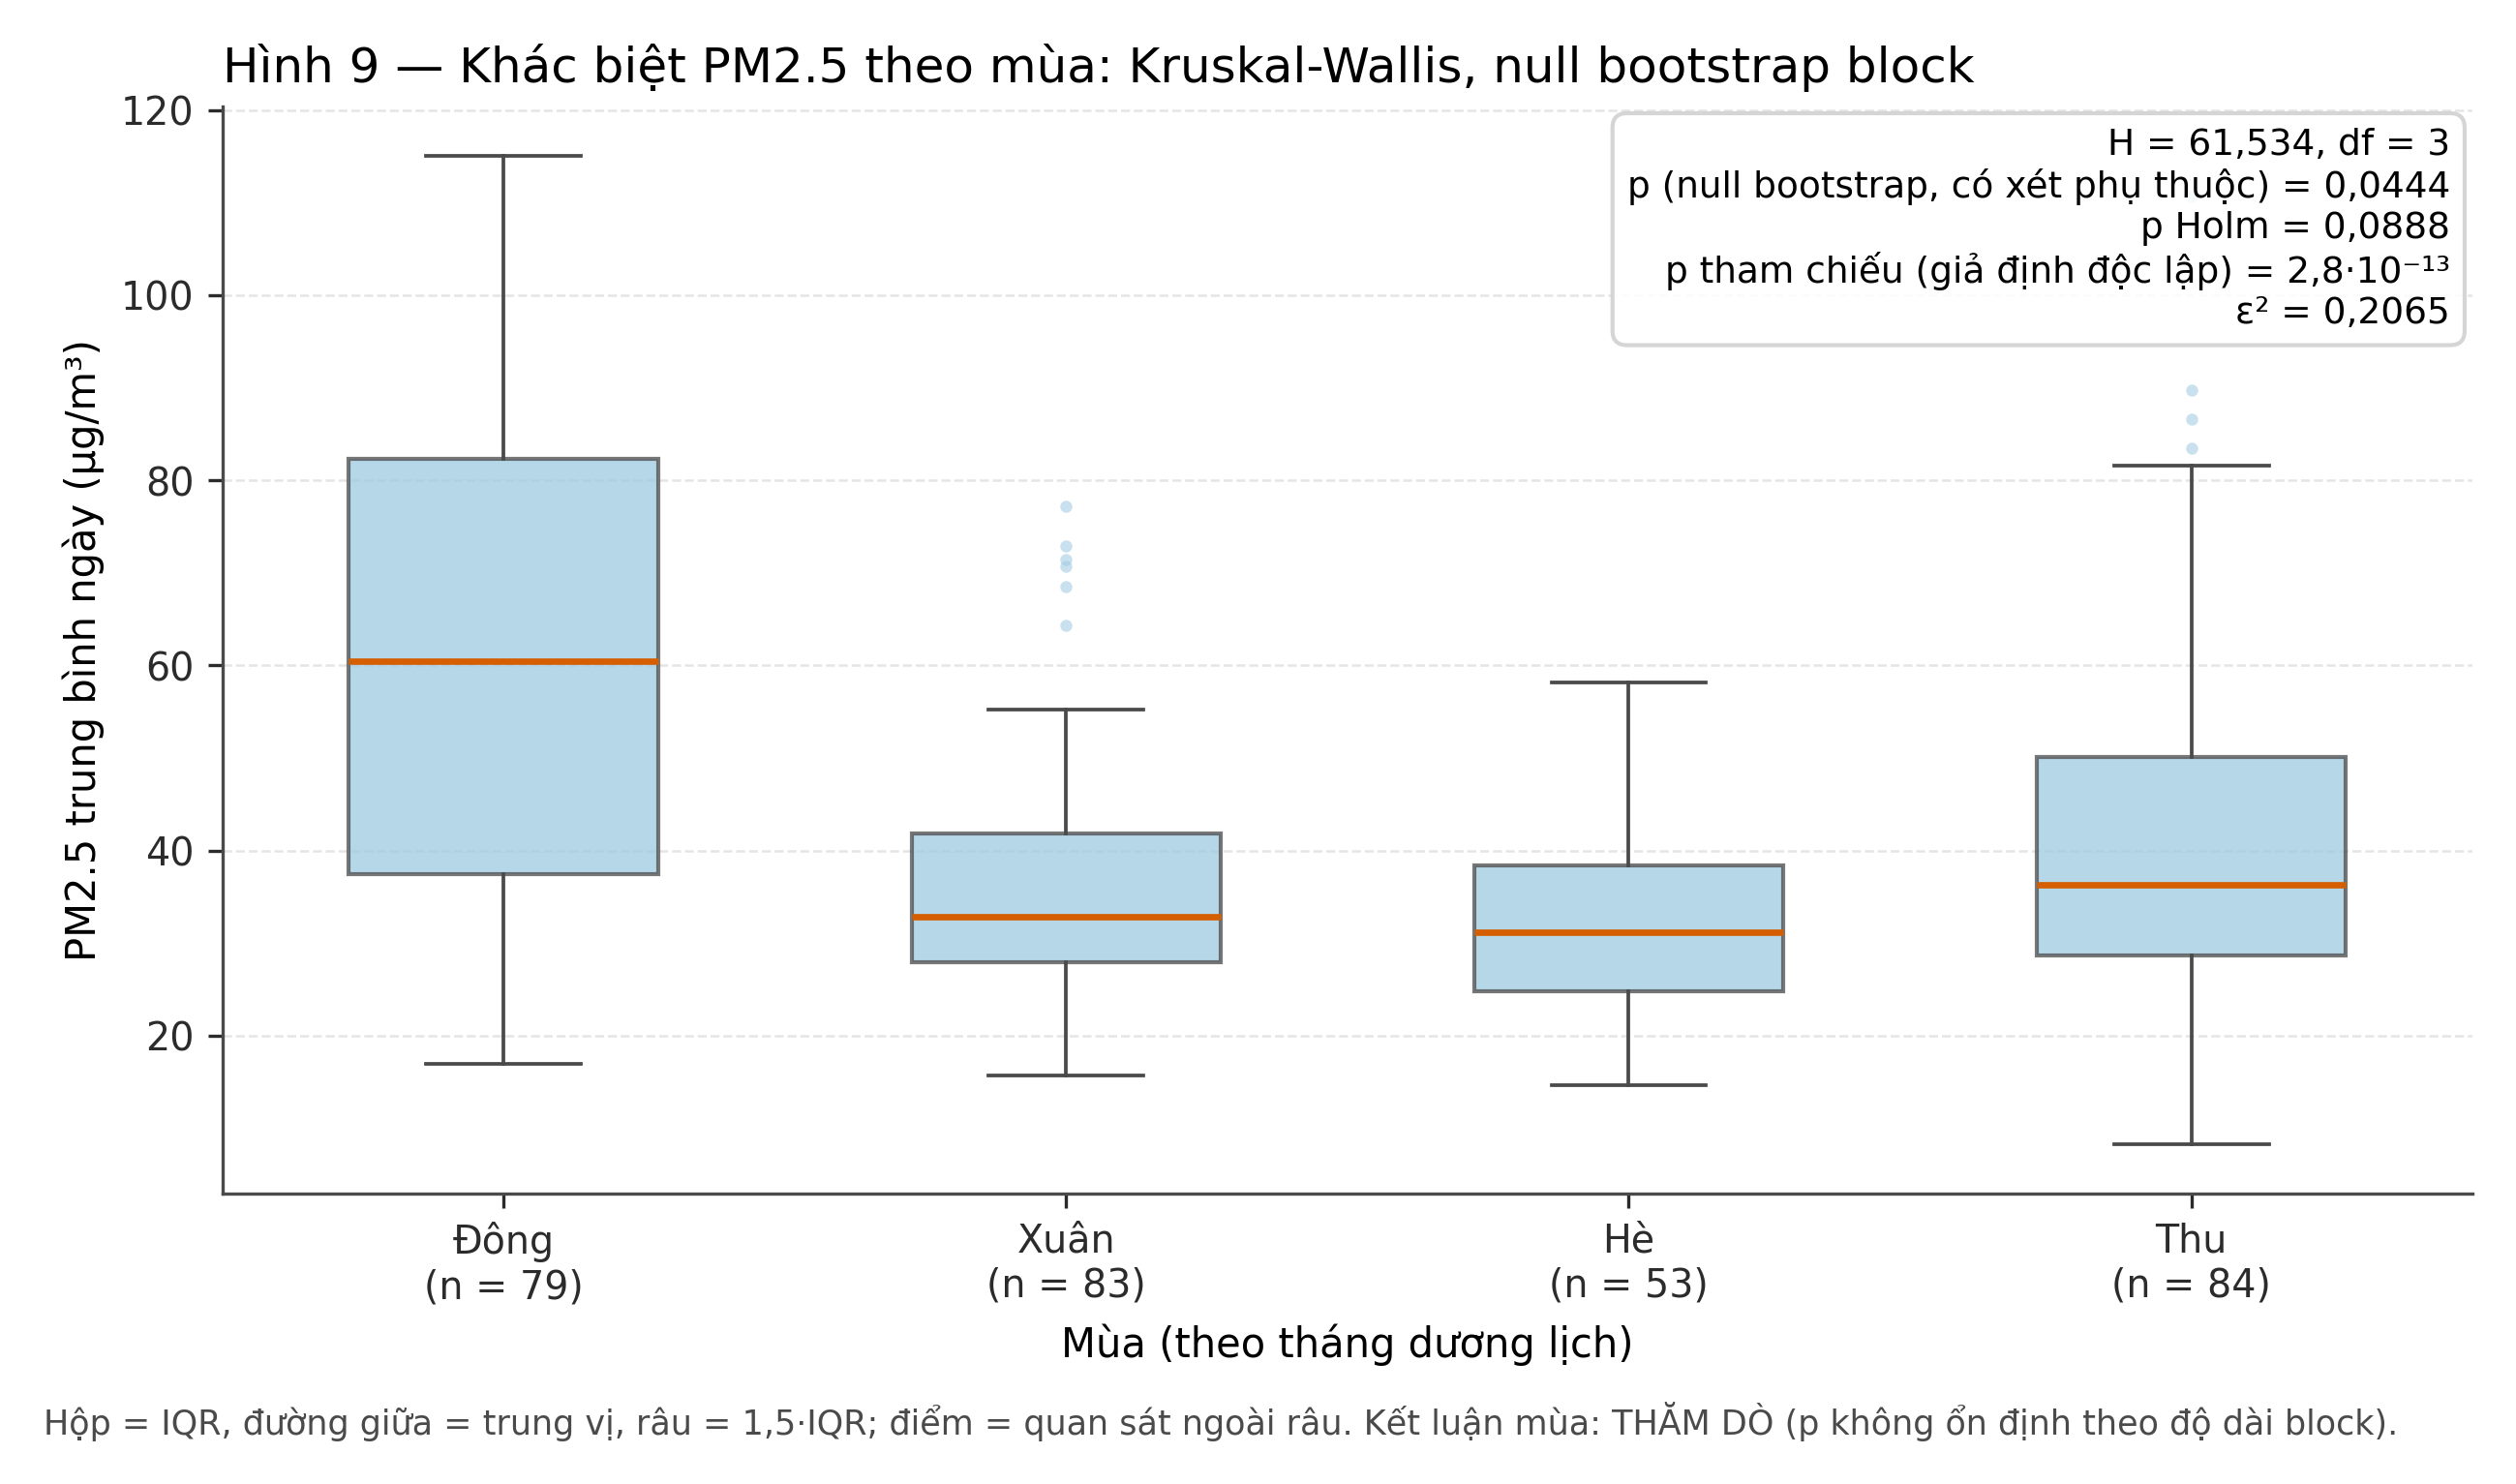

In [12]:
display_image(Image(filename=str(FIGURES["season"]), width=760))


---

## 7. Kiểm định 2 — Ngày làm việc vs ngày cuối tuần

- **H₀:** phân phối PM₂.₅ trung bình ngày của ngày làm việc bằng của ngày cuối tuần.
- **H₁:** hai phân phối khác nhau.
- **α = 0,05**, hai phía.

### 7.1. Phương pháp

- **Chính:** Mann-Whitney U với **null circular moving block bootstrap** trên chuỗi
  **gộp**; nhãn weekday/weekend **giữ theo vị trí lịch** → cấu trúc tuần không bị
  phá vỡ.
- **Đối chứng:** hồi quy **HAC/Newey–West** `[1, xu hướng, dummy cuối tuần]`.

Effect size $r_{rb} = 2U/(n_1 n_2) - 1$, quy ước **dương = ngày làm việc cao hơn** —
quy ước này được ghi ngay trong module để không ai đảo dấu.

### 7.2. "Không bác bỏ H₀" không có nghĩa "hai nhóm bằng nhau"

Đây là chỗ dễ đọc sai nhất. Báo cáo kèm **MDE** — chênh lệch nhỏ nhất phát hiện
được ở power 80%, α = 0,05, tính hậu nghiệm từ SD quan sát (công thức này **giả định
độc lập**, nên với chuỗi tự tương quan nó **đánh giá thấp** ngưỡng phân giải thực tế):

$$\text{MDE} = (z_{1-\alpha/2} + z_{\text{power}}) \cdot s_{\text{pooled}} \cdot \sqrt{\tfrac{1}{n_1} + \tfrac{1}{n_2}}$$

MDE là **ngưỡng phân giải của phép kiểm**, không phải kết luận về hiệu ứng.


In [13]:
weekday = tests["weekday_effect"]
mde = sensitivity["power_mde"]
weekday_ci = weekday["ci"]

print(f"Ngày làm việc: n = {format_int_vi(weekday['n_a'])}, trung vị {format_number_vi(weekday['median_a'])} µg/m³")
print(f"Ngày cuối tuần: n = {format_int_vi(weekday['n_b'])}, trung vị {format_number_vi(weekday['median_b'])} µg/m³")
print(f"U = {format_number_vi(weekday['statistic'], 1)} · p (null bootstrap) = {p_text(weekday['p_value'])} · "
      f"p Holm = {p_text(weekday['p_holm'])}")
print(f"p tham chiếu (giả định độc lập) = {p_text(weekday['p_value_independence'])}")
print(f"Đối chứng HAC: t = {format_number_vi(weekday['supporting_result']['statistic'], 3)}, "
      f"p = {p_text(weekday['supporting_result']['p_value'])}")
print(f"Chênh lệch trung vị (weekday − weekend) = {format_number_vi(weekday['median_difference'])} µg/m³, "
      f"CI 95% {ci_text(weekday_ci)}")
print(f"r_rb = {format_number_vi(weekday['effect_size'], 4)}  (dương = ngày làm việc cao hơn)")
print(f"MDE ≈ {format_number_vi(mde['mde'])} µg/m³ "
      f"(SD gộp {format_number_vi(mde['pooled_sd'])}; power {mde['power']:.0%}; α = {mde['alpha']})")

print("\nĐộ nhạy theo độ dài block:")
for name, entry in sorted(weekday["sensitivity"]["block_length"].items(), key=lambda kv: int(kv[0])):
    print(f"  block {name:>2} ngày: p = {p_text(entry['p_value'])}")

ci_includes_zero = weekday_ci["ci_low"] <= 0.0 <= weekday_ci["ci_high"]
print(f"\nTrạng thái kết luận: {status_text(weekday['status'])} — {weekday['status_reason']}")
print(f"CI chứa 0: {ci_includes_zero} · |chênh lệch| < MDE: {abs(weekday['median_difference']) < mde['mde']}")
assert weekday["p_holm"] >= ALPHA
assert ci_includes_zero


Ngày làm việc: n = 213, trung vị 36,72 µg/m³
Ngày cuối tuần: n = 86, trung vị 39,45 µg/m³
U = 8083,0 · p (null bootstrap) = 0,0780 · p Holm = 0,0888
p tham chiếu (giả định độc lập) = 0,1120
Đối chứng HAC: t = 1,611, p = 0,1082
Chênh lệch trung vị (weekday − weekend) = −2,74 µg/m³, CI 95% [−20,12; 6,21]
r_rb = −0,1175  (dương = ngày làm việc cao hơn)
MDE ≈ 7,75 µg/m³ (SD gộp 21,65; power 80%; α = 0.05)

Độ nhạy theo độ dài block:
  block  7 ngày: p = 0,0788
  block 14 ngày: p = 0,0840
  block 21 ngày: p = 0,0828
  block 28 ngày: p = 0,0780
  block 42 ngày: p = 0,0792

Trạng thái kết luận: XÁC NHẬN — Phương pháp chính và phương pháp đối chứng cùng chiều.
CI chứa 0: True · |chênh lệch| < MDE: True


**Đọc kết quả.** Không bác bỏ H₀ — và kết luận này **ổn định** theo độ dài block.
Nhưng vì chênh lệch quan sát **nhỏ hơn MDE** và CI chứa 0, kết luận đúng là: *dữ liệu
không đủ độ phân giải để kết luận có hay không một khác biệt nhỏ hơn MDE* — **không**
phải "ngày làm việc và cuối tuần bằng nhau". Ước lượng điểm còn nằm trong khoảng sai
số thực hành của một trạm đo, nên không được dùng để quy kết nguồn phát thải hay hành
vi giao thông.


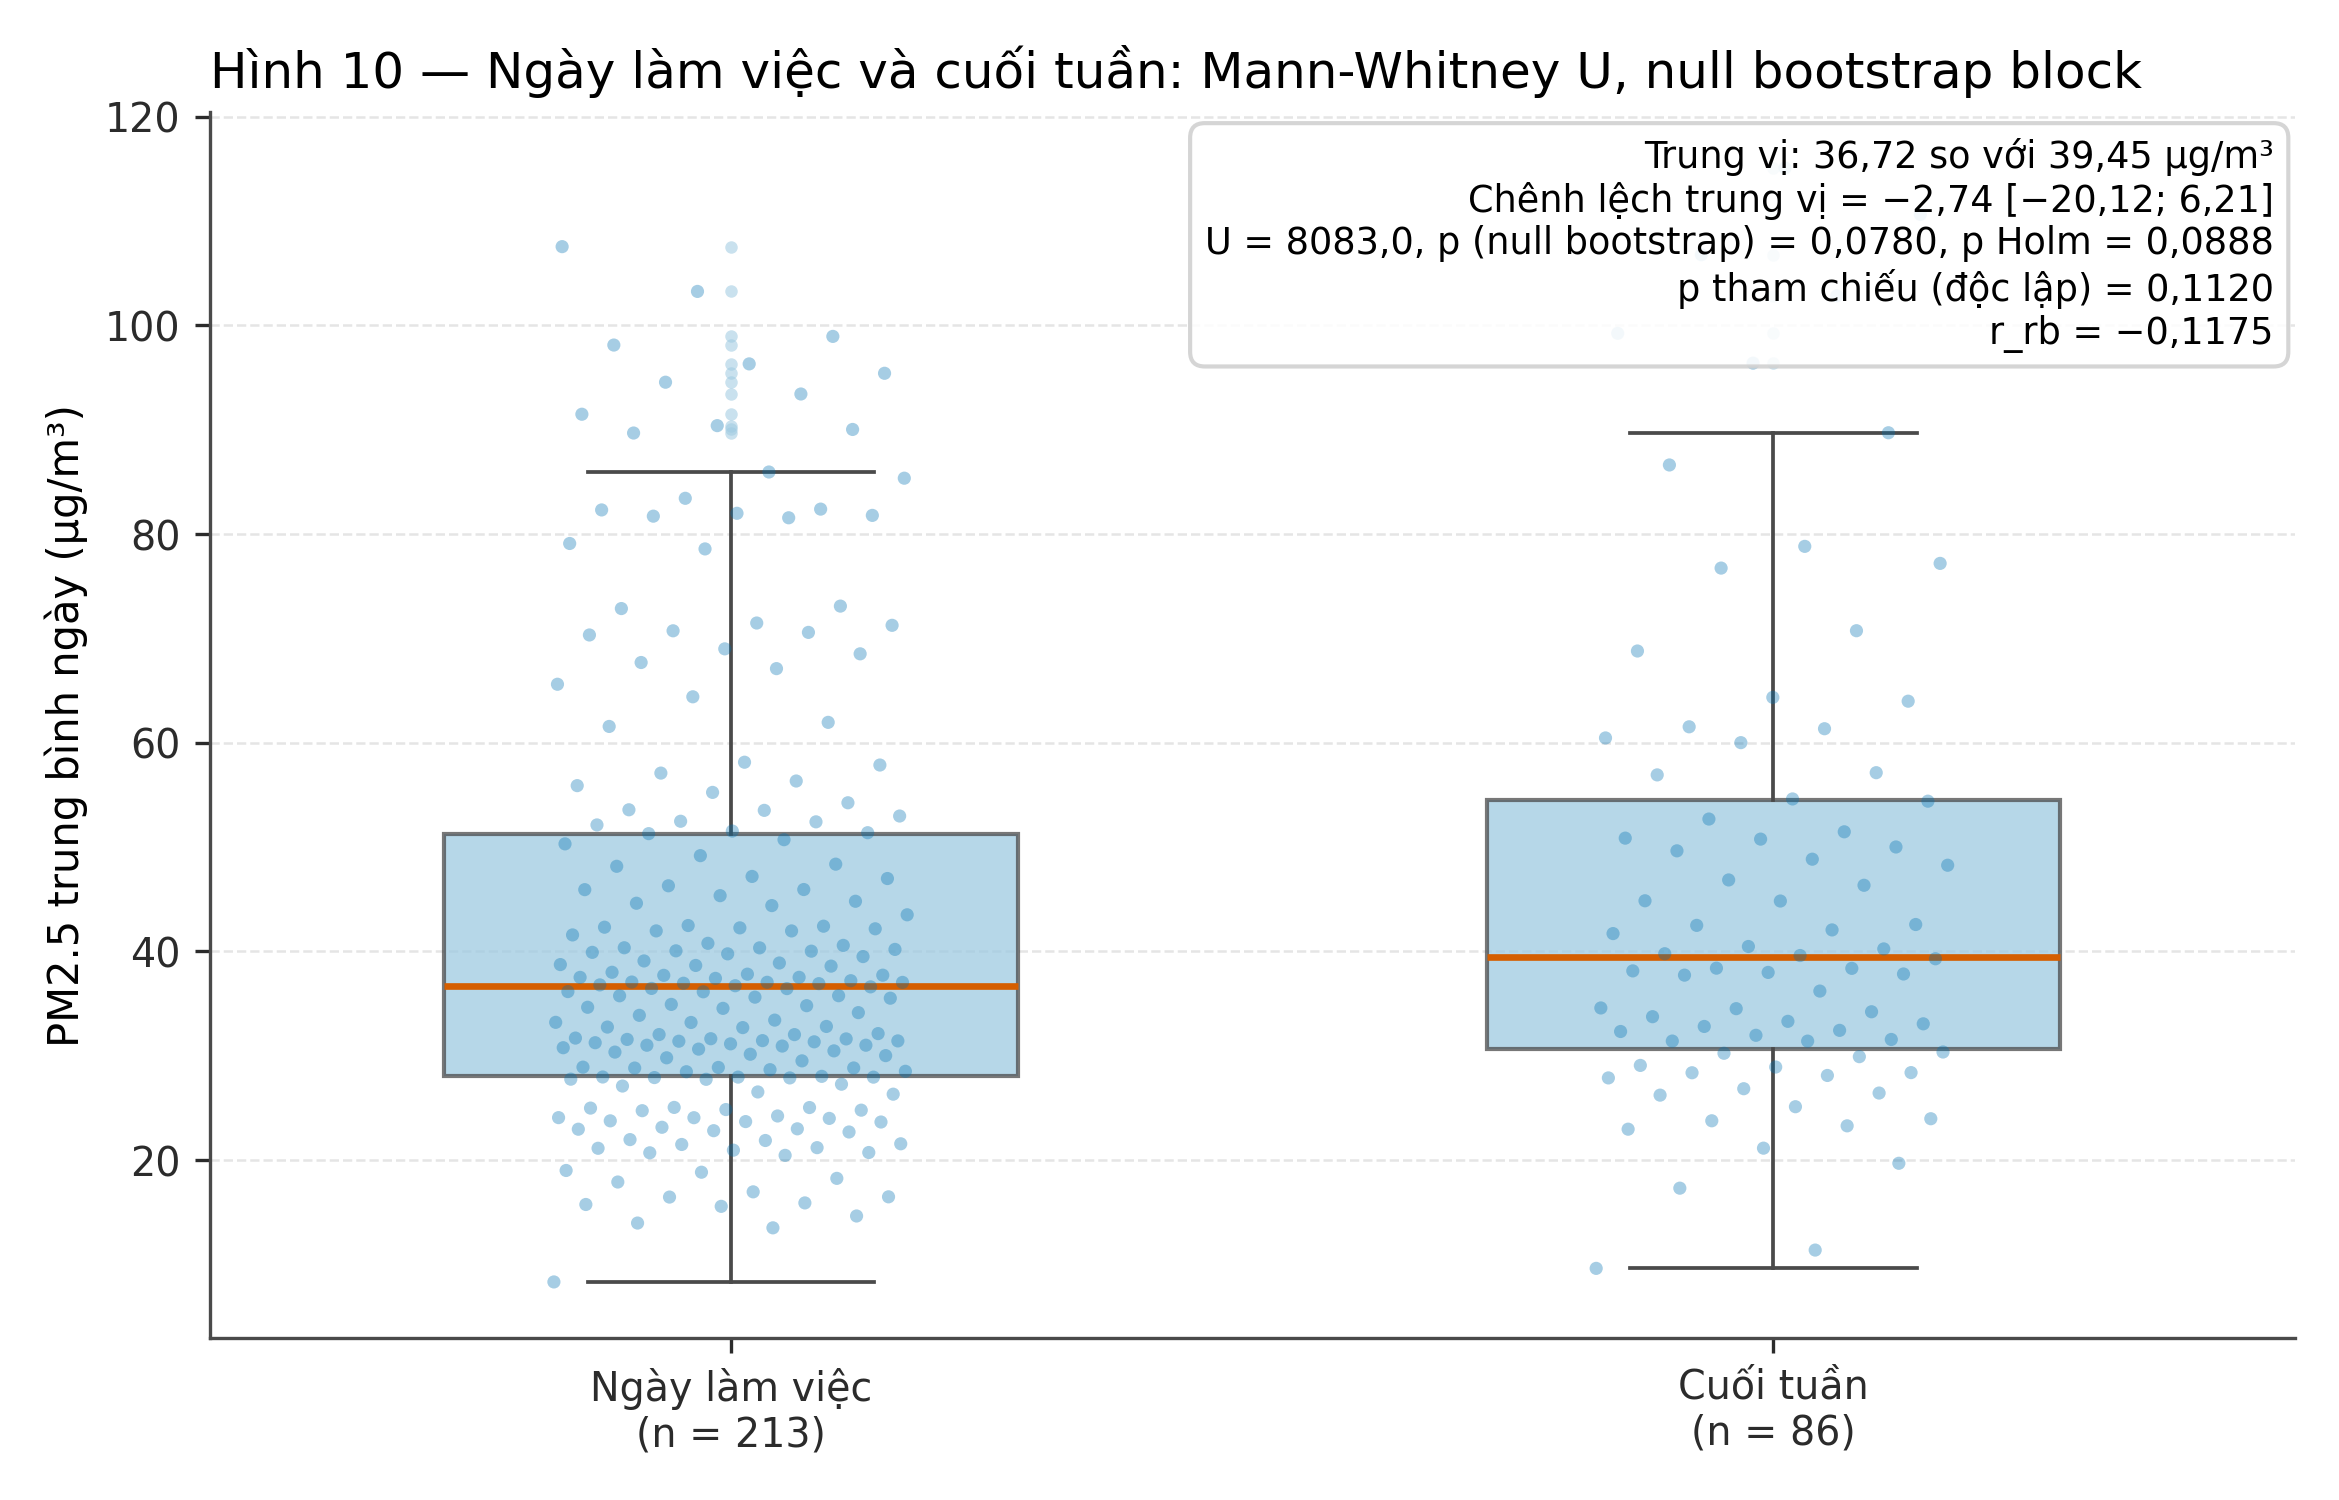

In [14]:
display_image(Image(filename=str(FIGURES["weekday"]), width=760))


---

## 8. Kiểm định 3 — Đối chiếu QCVN 05:2023/BTNMT, đúng chu kỳ lấy mẫu

Hai ngưỡng được kiểm định **tách biệt**, mỗi ngưỡng đi với đúng chu kỳ trung bình của
nó:

| Ngưỡng | Giá trị | Đơn vị áp dụng | Phương pháp | Tham số so sánh |
|---|---|---|---|---|
| Trung bình **24 giờ** | 50 µg/m³ | Trung bình của 24 giờ | HAC/Newey–West trên **tỷ lệ vượt ngưỡng** | **Trung vị** của trung bình ngày (tương đương P(>50) = 0,5) |
| Trung bình **năm** | 25 µg/m³ | Trung bình của một năm | HAC/Newey–West (hệ số chặn) | **Trung bình** của trung bình ngày |

Không có phép so sánh nào giữa **một giờ** với ngưỡng ngày/năm.

### 8.1. Ngưỡng 24 giờ — 50 µg/m³

- **H₀:** P(trung bình ngày > 50) = 0,5 (tương đương trung vị = 50 với phân phối liên tục).
- **H₁:** khác 0,5.
- **α = 0,05**, hai phía.

Vì sao tỷ lệ vượt ngưỡng chứ không phải signed-rank: với chuỗi tự tương quan mạnh,
dãy **chênh lệch lớn** (ngày vượt ngưỡng rất nhiều) rất bền → SE HAC của thống kê
signed-rank bị thổi phồng, làm phép kiểm **mất sức mạnh** một cách không cần thiết.
Thống kê tỷ lệ vượt có cùng H₀ và ổn định hơn; bản signed-rank có HAC vẫn được
tính và in ra như **đối chứng**.

### 8.2. Ngưỡng năm — 25 µg/m³

- **H₀:** E(trung bình ngày) = 25.
- **H₁:** khác 25.
- **α = 0,05**, hai phía.

> **Giới hạn thiết kế:** dải dữ liệu 07/2025–07/2026 **không** trùng năm dương lịch.
> Đại lượng được kiểm định là trung bình **giai đoạn quan sát**, không phải "trung
> bình năm" theo định nghĩa quy chuẩn. Nó là chỉ báo mức nền, không phải phán quyết
> tuân thủ.

### 8.3. Hai mẫu số, hai câu hỏi — không được trộn

| Cách đếm | Tử số | Mẫu số | Trả lời câu hỏi |
|---|---|---|---|
| Cửa sổ trượt 24 giờ | Số cửa sổ ≥ 50 | Số cửa sổ hợp lệ | "Bao nhiêu phần trăm **cửa sổ 24 giờ** vượt ngưỡng?" |
| Trung bình ngày | Số ngày ≥ 50 | Số ngày đủ độ phủ | "Bao nhiêu phần trăm **ngày** vượt ngưỡng?" |

Ghép tử số của cách này với mẫu số của cách kia sẽ cho ra một tỷ lệ **không ứng với
đơn vị nào**. Ví dụ cụ thể được in ở cell dưới.


In [15]:
q24 = tests["qcvn_24h"]
annual = tests["qcvn_annual"]

print(f"[24 giờ] n = {format_int_vi(q24['n'])} ngày · trung vị {format_number_vi(q24['median'])} µg/m³")
print(f"  t (tỷ lệ vượt ngưỡng, HAC) = {format_number_vi(q24['statistic'], 4)}")
print(f"  p (hiệu chỉnh phụ thuộc) = {p_text(q24['p_value'])} · p Holm = {p_text(q24['p_holm'])}")
print(f"  p tham chiếu (Wilcoxon, giả định độc lập) = {p_text(q24['p_value_independence'])}")
print(f"  đối chứng: null-imposed bootstrap p = {p_text(q24['supporting_result']['null_imposed_p'])}, "
      f"p đảo CI = {p_text(q24['supporting_result']['percentile_p'])}, "
      f"signed-rank HAC p = {p_text(q24['supporting_result']['signed_rank_hac_p'])}")
print(f"  r = {format_number_vi(q24['effect_size'], 4)} (âm = dưới ngưỡng)")
print(f"  CI 95% block bootstrap cho trung vị: {ci_text(q24['ci_bootstrap'])}")

print()
print(f"[Năm] n = {format_int_vi(annual['n'])} ngày · trung bình {format_number_vi(annual['mean'])} "
      f"± {format_number_vi(annual['sd'])} µg/m³")
print(f"  t (HAC) = {format_number_vi(annual['statistic'], 4)} · df = {annual['n'] - 1}")
print(f"  p (hiệu chỉnh phụ thuộc) = {p_text(annual['p_value'])} · p Holm = {p_text(annual['p_holm'])}")
print(f"  p tham chiếu (t-test, giả định độc lập) = {p_text(annual['p_value_independence'])}")
print(f"  đối chứng: null-imposed bootstrap p = {p_text(annual['supporting_result']['null_imposed_p'])}, "
      f"p đảo CI = {p_text(annual['supporting_result']['percentile_p'])}")
print(f"  Cohen's d = {format_number_vi(annual['effect_size'], 4)}")
print(f"  CI 95% HAC: {ci_text(annual['hac_detail']['ci'])}")
print(f"  CI 95% block bootstrap: {ci_text(annual['ci_bootstrap'])}")
print(f"  CI 95% theo t (giả định độc lập — tham chiếu): {ci_text(annual['ci_t'])}")

assert q24["mu"] == QCVN_2023_PM25_24H_LIMIT == 50.0
assert annual["mu"] == QCVN_2023_PM25_ANNUAL_LIMIT == 25.0
assert q24["p_holm"] < ALPHA and annual["p_holm"] < ALPHA
assert q24["median"] < QCVN_2023_PM25_24H_LIMIT
assert annual["mean"] > QCVN_2023_PM25_ANNUAL_LIMIT
assert q24["status"] == "confirmatory" and annual["status"] == "confirmatory"

# CI HAC phải rộng hơn CI giả định độc lập — nếu bằng nhau thì hiệu chỉnh không hoạt động.
assert annual["hac_detail"]["ci"]["ci_high"] > annual["ci_t"]["ci_high"]


[24 giờ] n = 299 ngày · trung vị 37,20 µg/m³
  t (tỷ lệ vượt ngưỡng, HAC) = −2,6558
  p (hiệu chỉnh phụ thuộc) = 0,0083 · p Holm = 0,0250
  p tham chiếu (Wilcoxon, giả định độc lập) = 7,88·10⁻¹⁰
  đối chứng: null-imposed bootstrap p = 0,0064, p đảo CI = 0,0072, signed-rank HAC p = 0,0493
  r = −0,4102 (âm = dưới ngưỡng)
  CI 95% block bootstrap cho trung vị: [32,81; 45,36]

[Năm] n = 299 ngày · trung bình 43,38 ± 21,68 µg/m³
  t (HAC) = 4,3535 · df = 298
  p (hiệu chỉnh phụ thuộc) = 1,84·10⁻⁵ · p Holm = 7,38·10⁻⁵
  p tham chiếu (t-test, giả định độc lập) = 5,33·10⁻³⁷
  đối chứng: null-imposed bootstrap p = 0,0004, p đảo CI = 0,0006
  Cohen's d = 0,8476
  CI 95% HAC: [35,07; 51,69]
  CI 95% block bootstrap: [35,75; 52,32]
  CI 95% theo t (giả định độc lập — tham chiếu): [40,91; 45,85]


In [16]:
wilson = context["panel_days_equal_or_over_ci"]
ctx_rows = [
    ("Cửa sổ trượt 24 giờ hợp lệ", format_int_vi(context["rolling_windows_valid"])),
    ("Cửa sổ ≥ 50 µg/m³", format_int_vi(context["rolling_windows_over"])),
    ("Tỷ lệ cửa sổ vượt", pct(context["rolling_share"])),
    ("Ngày đủ độ phủ", format_int_vi(context["panel_days"])),
    ("Ngày có trung bình ≥ 50 µg/m³", format_int_vi(context["panel_days_over"])),
    ("Tỷ lệ ngày vượt", pct(context["panel_share"])),
    ("CI 95% Wilson cho tỷ lệ ngày", f"[{pct(wilson[0])}; {pct(wilson[1])}]"),
    ("Dòng giờ trong dataset", format_int_vi(context["hourly_rows"])),
]
display(pd.DataFrame(ctx_rows, columns=["Cách đếm", "Giá trị"]))

wrong_share = context["rolling_windows_over"] / context["hourly_rows"]
print(f"Ví dụ ghép SAI (tử số cửa sổ / mẫu số giờ): "
      f"{format_int_vi(context['rolling_windows_over'])}/{format_int_vi(context['hourly_rows'])} "
      f"= {pct(wrong_share)} — không ứng với đơn vị nào, không dùng trong báo cáo.")
print(f"→ Tỷ lệ ngày vượt ngưỡng 24h: {context['panel_days_over']}/{context['panel_days']} "
      f"= {pct(context['panel_share'])}.")
assert context["panel_days"] == n_days
assert context["rolling_windows_valid"] != context["hourly_rows"]
assert abs(context["panel_share"] - context["panel_days_over"] / n_days) < 1e-12


,Cách đếm,Giá trị
0,Cửa sổ trượt 24 giờ hợp lệ,5.317
1,Cửa sổ ≥ 50 µg/m³,1.655
2,Tỷ lệ cửa sổ vượt,"31,13%"
3,Ngày đủ độ phủ,299
4,Ngày có trung bình ≥ 50 µg/m³,84
5,Tỷ lệ ngày vượt,"28,09%"
6,CI 95% Wilson cho tỷ lệ ngày,"[23,30%; 33,44%]"
7,Dòng giờ trong dataset,9.044


Ví dụ ghép SAI (tử số cửa sổ / mẫu số giờ): 1.655/9.044 = 18,30% — không ứng với đơn vị nào, không dùng trong báo cáo.
→ Tỷ lệ ngày vượt ngưỡng 24h: 84/299 = 28,09%.


**Không kết luận "đạt/không đạt QCVN".** Kết quả trên nói hai điều không mâu thuẫn:
vị trí trung tâm của phân phối trung bình ngày nằm **dưới** 50 µg/m³, nhưng gần ba
phần mười số ngày **vượt** ngưỡng đó. Quy chuẩn quy định cách đánh giá tuân thủ
riêng — dự án không mã hoá quy tắc đó và không có văn bản gốc đối chiếu, nên báo
cáo dừng ở mức **kiểm định vị trí phân phối so với ngưỡng**.


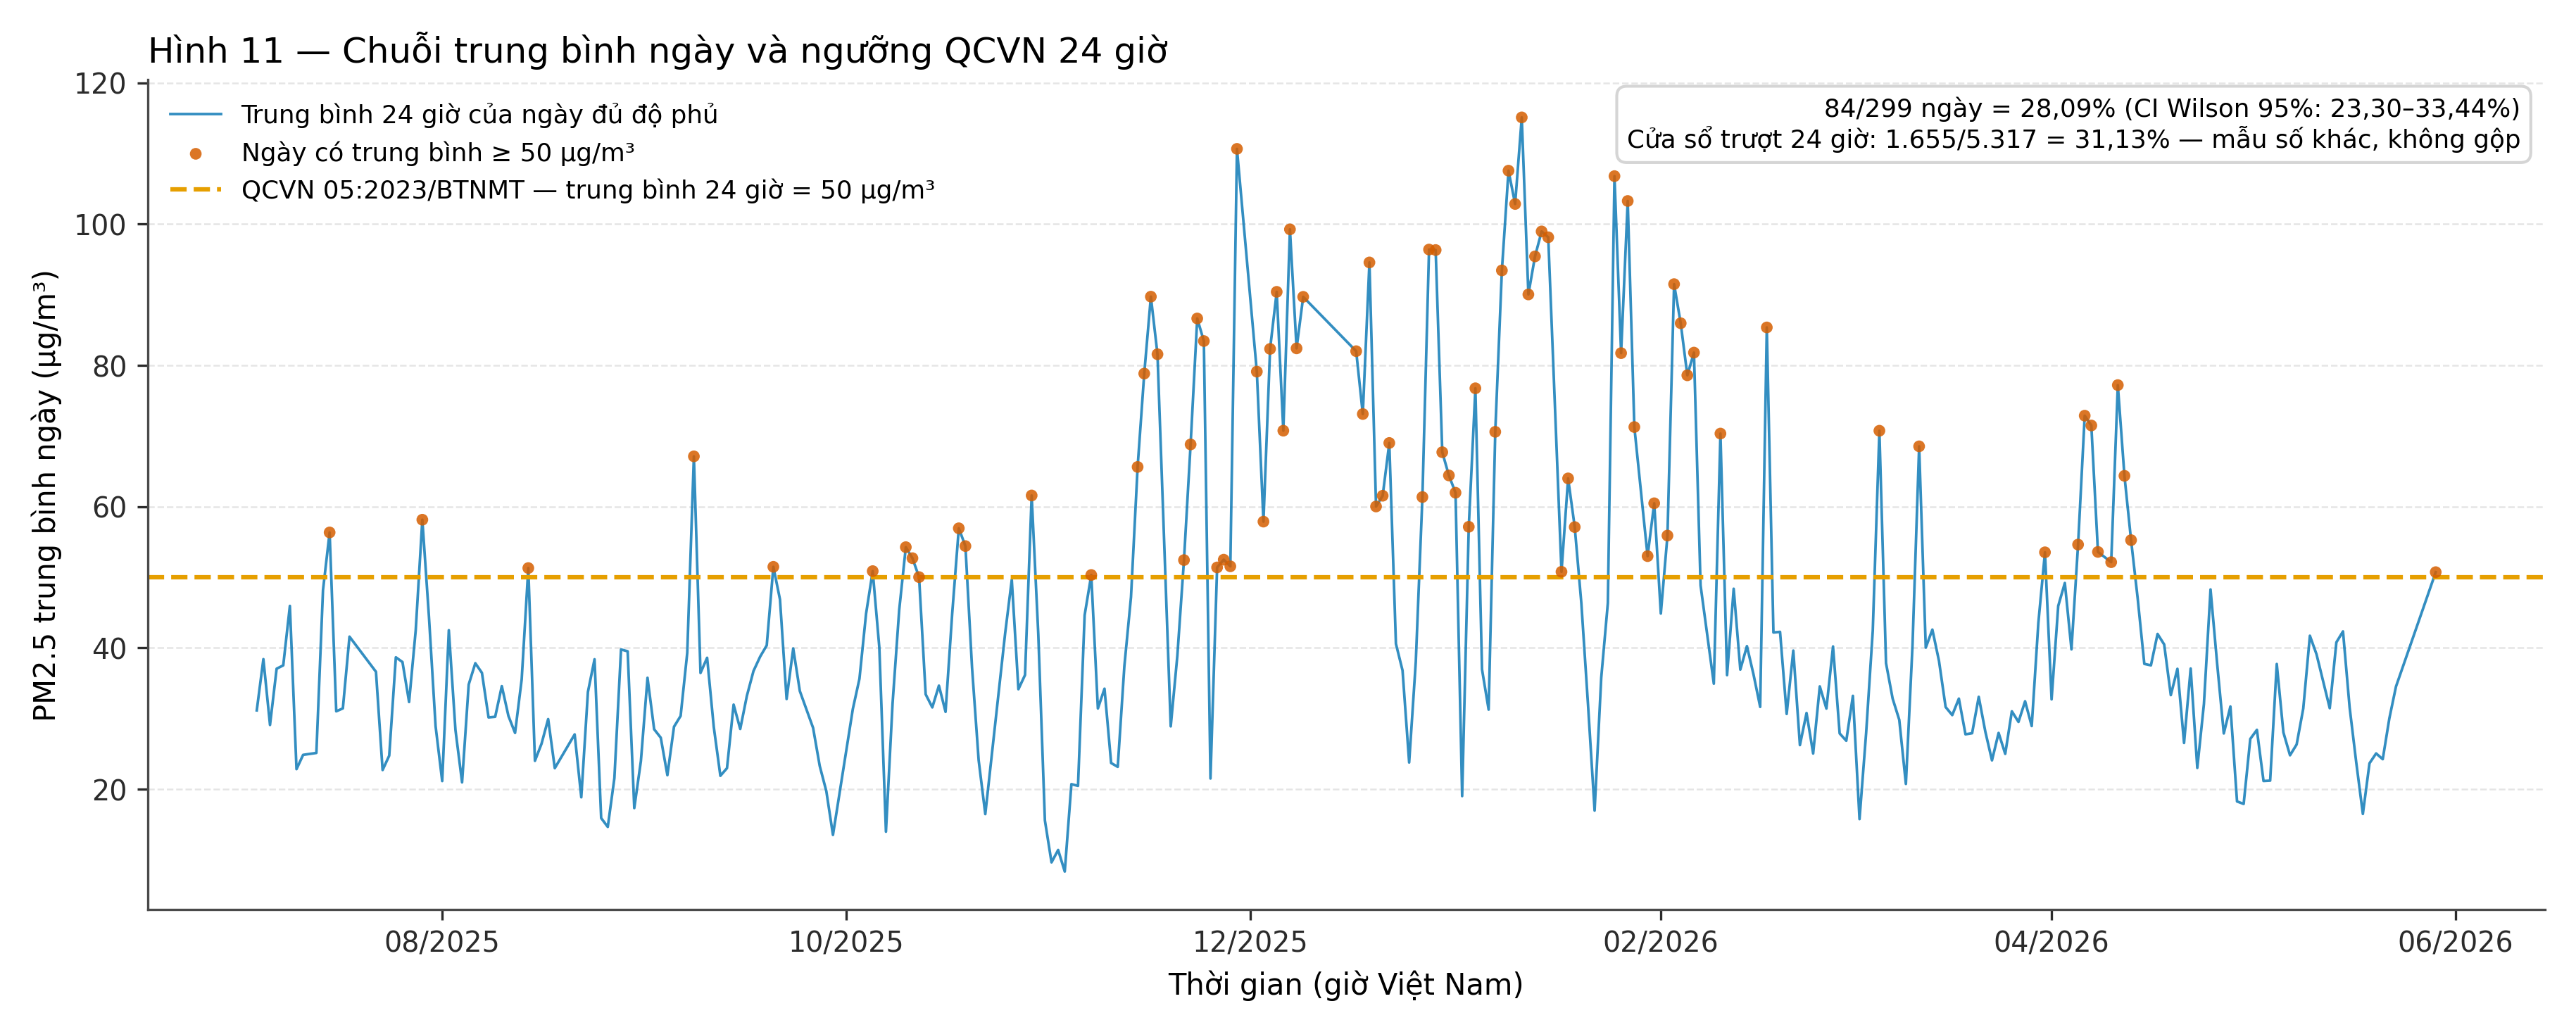

In [17]:
display_image(Image(filename=str(FIGURES["qcvn"]), width=760))


---

## 9. Kiểm soát sai lầm loại I bằng mô phỏng dưới H₀

Một phép kiểm hợp lệ phải bác bỏ H₀ khoảng **5%** số lần khi H₀ đúng. Vì dữ liệu
thật chỉ có một lần rút, mô phỏng là cách **định lượng** xem phép kiểm nào thực sự
kiểm soát được sai lầm loại I trên dữ liệu tự tương quan.

Mô phỏng dùng chuỗi **AR(1)** có cùng mức tự tương quan như dữ liệu thật
(ρ = ACF bậc 1 quan sát), cùng cỡ mẫu, cùng cách nhóm, cùng tham số phụ thuộc. Ở mỗi
lần lặp, cả ba cách tính p (tham chiếu, phương pháp chính, phương pháp đối chứng)
đều được áp dụng trên **cùng một** chuỗi mô phỏng.


In [18]:
size_rows = []
for name, entry in simulation["size"].items():
    power = simulation["power"][name]
    size_rows.append({
        "Phép kiểm": name,
        "size (tham chiếu)": pct(entry["size_independence"], 1),
        "size (chính)": pct(entry["size_dependence_aware"], 1),
        "size (đối chứng)": pct(entry["size_supporting"], 1),
        "power (tham chiếu)": pct(power["size_independence"], 1),
        "power (chính)": pct(power["size_dependence_aware"], 1),
        "power (đối chứng)": pct(power["size_supporting"], 1),
    })
display(pd.DataFrame(size_rows))

print(f"ρ mô phỏng = {format_number_vi(simulation['rho_used'], 4)} · n = {format_int_vi(simulation['n_days'])} "
      f"ngày · {format_int_vi(simulation['n_sim'])} lần lặp · α = {ALPHA}")
print("→ 'size' là tỷ lệ bác bỏ H₀ khi H₀ đúng; 'power' là tỷ lệ bác bỏ khi có hiệu ứng.")
print("→ Phép kiểm giả định độc lập bác bỏ hàng chục tới gần 80% số lần dưới H₀: bằng chứng")
print("  định lượng rằng p-value SciPy KHÔNG kiểm soát được sai lầm loại I trên dữ liệu này.")
print("→ Phương pháp có xét phụ thuộc đưa tỷ lệ này về gần α (vẫn hơi lạc quan ~2–3 lần α).")


,Phép kiểm,size (tham chiếu),size (chính),size (đối chứng),power (tham chiếu),power (chính),power (đối chứng)
0,season,"75,0%","8,0%","31,0%","93,0%","34,0%","58,0%"
1,weekday,"2,0%","2,0%","5,0%","100,0%","100,0%","100,0%"
2,median,"36,0%","5,0%","3,0%","100,0%","100,0%","100,0%"
3,mean,"39,0%","8,0%","8,0%","100,0%","100,0%","100,0%"


ρ mô phỏng = 0,7276 · n = 299 ngày · 100 lần lặp · α = 0.05
→ 'size' là tỷ lệ bác bỏ H₀ khi H₀ đúng; 'power' là tỷ lệ bác bỏ khi có hiệu ứng.
→ Phép kiểm giả định độc lập bác bỏ hàng chục tới gần 80% số lần dưới H₀: bằng chứng
  định lượng rằng p-value SciPy KHÔNG kiểm soát được sai lầm loại I trên dữ liệu này.
→ Phương pháp có xét phụ thuộc đưa tỷ lệ này về gần α (vẫn hơi lạc quan ~2–3 lần α).


---

## 10. Khả năng khái quát hóa kết quả theo mùa

Bốn kiểm định trên **không** trả lời được: khác biệt mùa quan sát ở giai đoạn
07/2025–07/2026 có phải là quy luật mùa vụ ổn định nhiều năm không? Bốn dữ kiện dưới
đây nói: **không thể khẳng định**.

1. **Chỉ một chu kỳ mùa** — mỗi mùa là một *đoạn thời gian liên tiếp*, nên "mùa" và
   "thời gian" là hai cách gọi của cùng một biến.
2. **Xu hướng thời gian cùng cỡ với khác biệt mùa** — hai cấu phần cạnh tranh.
3. **Mẫu không cân bằng, thiếu hụt không ngẫu nhiên.**
4. **Không mùa nào có mặt ở hai mùa-vụ khác nhau** → không thể kiểm tra tính ổn định
   giữa các năm.


In [19]:
gen = generalization
cov_rows = []
for season_key in SEASON_DISPLAY_ORDER:
    cov = gen["coverage"][season_key]
    cov_rows.append({
        "Mùa": SEASON_LABELS_VI[season_key],
        "Ngày lịch": format_int_vi(cov["calendar_days"]),
        "Ngày giữ lại": format_int_vi(cov["kept_days"]),
        "Ngày bị loại": format_int_vi(cov["dropped_days"]),
        "Tỷ lệ giữ lại": pct(cov["kept_share"], 1),
    })
display(pd.DataFrame(cov_rows))

breakdown = gen["season_year_breakdown"]
display(breakdown.rename(columns={
    "season": "Mùa (mã)", "season_year": "Mùa-vụ", "size": "n ngày",
    "median": "Trung vị", "min": "Min", "max": "Max",
}))

print(f"Số chu kỳ mùa quan sát được: {gen['n_seasonal_cycles']}")
print(f"Xu hướng tuyến tính: {format_number_vi(gen['trend_per_month'])} µg/m³ mỗi tháng "
      f"({format_number_vi(abs(gen['trend_over_period']), 1)} µg/m³ trên cả năm)")
print(f"Khác biệt mùa lớn nhất: {format_number_vi(gen['max_season_contrast'], 2)} µg/m³ "
      f"→ tỷ lệ xu hướng / khác biệt = {format_number_vi(gen['trend_to_contrast_ratio'] * 100, 0)}%")
print(f"Mùa xuất hiện ở ≥ 2 mùa-vụ: {gen['seasons_with_multiple_years'] or 'không có'}")
print("\n→ Kết luận mùa là MÔ TẢ của một giai đoạn quan sát duy nhất, ở một trạm;")
print("  không có bằng chứng cho quy luật mùa vụ ổn định nhiều năm.")


,Mùa,Ngày lịch,Ngày giữ lại,Ngày bị loại,Tỷ lệ giữ lại
0,Đông,90,79,11,"87,8%"
1,Xuân,90,83,7,"92,2%"
2,Hè,59,53,6,"89,8%"
3,Thu,91,84,7,"92,3%"


,Mùa (mã),Mùa-vụ,n ngày,Trung vị,Min,Max
0,Dong,2026,79,60.463768,16.960321,115.090047
1,He,2025,53,31.144495,14.646018,58.136647
2,Thu,2025,84,36.297014,8.325257,110.638399
3,Xuan,2026,83,32.811997,15.748536,77.194215


Số chu kỳ mùa quan sát được: 1
Xu hướng tuyến tính: −2,29 µg/m³ mỗi tháng (27,4 µg/m³ trên cả năm)
Khác biệt mùa lớn nhất: 29,32 µg/m³ → tỷ lệ xu hướng / khác biệt = 94%
Mùa xuất hiện ở ≥ 2 mùa-vụ: không có

→ Kết luận mùa là MÔ TẢ của một giai đoạn quan sát duy nhất, ở một trạm;
  không có bằng chứng cho quy luật mùa vụ ổn định nhiều năm.


---

## 11. Kiểm tra độ nhạy (exploratory, không thuộc family nào)

### 11.1. Ghép cặp theo tuần cho weekday/weekend

Mỗi tuần ISO đủ điều kiện (≥ 3 ngày trong tuần và ≥ 2 ngày cuối tuần) cho **một**
chênh lệch. Cách này loại bỏ biến thiên "tuần này bẩn hơn tuần kia" — thứ tự tương
quan mạnh nhất còn lại sau khi đã lấy trung bình ngày. Các chênh lệch tuần cũng tự
tương quan, nên phép thử dùng **signed-rank có HAC** (lag 4 tuần).

### 11.2. Kruskal-Wallis trên trung bình tuần theo mùa

Nếu khác biệt mùa chỉ là hệ quả của việc coi từng ngày là độc lập, phép thử ở mức
tuần sẽ yếu đi rõ rệt. Ở mức tuần cỡ mẫu nhỏ hơn nhiều nên power thấp — p không có
ý nghĩa **không** phủ định kết quả mức ngày.


In [20]:
paired = sensitivity["paired_weeks"]
weekly_season = sensitivity["season_weekly"]["weekly_kruskal"]

print("11.1. Ghép cặp theo tuần (weekday − weekend)")
print(f"  Số tuần đủ điều kiện: {format_int_vi(paired['n_weeks'])} "
      f"(≥ {paired['min_weekdays']} ngày trong tuần, ≥ {paired['min_weekend_days']} ngày cuối tuần)")
print(f"  Trung vị chênh lệch: {format_number_vi(paired['median_difference'])} µg/m³, "
      f"CI 95% {ci_text(paired['ci'])}")
print(f"  Tỷ lệ tuần có weekday cao hơn: {pct(paired['share_weekday_higher'], 1)}")
print(f"  Signed-rank có HAC trên {format_int_vi(paired['test']['n'])} chênh lệch tuần: "
      f"t = {format_number_vi(paired['test']['statistic'], 3)}, "
      f"p = {p_text(paired['test']['p_value'])}, "
      f"r = {format_number_vi(paired['test']['effect_size'], 4)}")
print(f"  p tham chiếu (giả định độc lập) = {p_text(paired['test']['p_value_independence'])}")
print(f"  → {'bác bỏ' if paired['test']['p_value'] < ALPHA else 'không bác bỏ'} H₀ ở α = {ALPHA}")

print()
print("11.2. Kruskal-Wallis trên trung bình tuần theo mùa")
print(f"  Số tuần dùng được: {format_int_vi(sensitivity['season_weekly']['n_weeks'])}")
print(f"  H = {format_number_vi(weekly_season['statistic'], 3)} · df = {weekly_season['df']} · "
      f"p (hiệu chỉnh) = {p_text(weekly_season['p_value'])} · "
      f"p tham chiếu = {p_text(weekly_season['p_value_independence'])} · "
      f"ε² = {format_number_vi(weekly_season['effect_size'], 4)}")

assert paired["n_weeks"] < n_days
assert weekly_season["n"] < n_days


11.1. Ghép cặp theo tuần (weekday − weekend)
  Số tuần đủ điều kiện: 40 (≥ 3 ngày trong tuần, ≥ 2 ngày cuối tuần)
  Trung vị chênh lệch: −2,70 µg/m³, CI 95% [−10,41; 2,69]
  Tỷ lệ tuần có weekday cao hơn: 37,5%
  Signed-rank có HAC trên 40 chênh lệch tuần: t = −1,433, p = 0,1598, r = −0,2317
  p tham chiếu (giả định độc lập) = 0,2064
  → không bác bỏ H₀ ở α = 0.05

11.2. Kruskal-Wallis trên trung bình tuần theo mùa
  Số tuần dùng được: 48
  H = 19,310 · df = 3 · p (hiệu chỉnh) = 0,0194 · p tham chiếu = 0,0002 · ε² = 0,4109


**Đọc kết quả.** Phép thử ghép cặp tuần cho cùng kết luận với kiểm định ở mục 7
(không bác bỏ H₀), nên kết luận weekday/weekend **không** phải sản phẩm của giả định
độc lập. Phép thử mùa ở mức tuần vẫn bác bỏ H₀ sau hiệu chỉnh, củng cố kết luận
mùa ở mức *mô tả*. Nếu hai phép thử này **đổi chiều** so với mức ngày, kết luận
đúng phải là "không ổn định" — và điều đó phải được viết ra chứ không bị bỏ qua.


---

## 12. Đọc p-value cho đúng (task 5.7)

p-value là xác suất **của dữ liệu, có điều kiện H₀ đúng** — không phải xác suất H₀
đúng, cũng không phải xác suất kết quả lặp lại. Bốn sai lầm thường gặp:

| Sai lầm | Vì sao sai | Cách đọc đúng trong báo cáo này |
|---|---|---|
| "p là xác suất H₀ đúng" | p tính **dưới giả định H₀**; nó không phải xác suất hậu nghiệm | Chỉ nói "dữ liệu không tương thích với H₀ ở mức α" |
| "1 − p là xác suất H₁ đúng" | H₁ thường là giả thuyết hợp, không có phân phối tiên nghiệm | Không gán xác suất cho H₁ |
| "p nhỏ = hiệu ứng lớn" | p phụ thuộc cỡ mẫu; n_eff ≈ 47 mới là cỡ mẫu có ý nghĩa ở đây | Luôn đọc kèm effect size và CI |
| "p > α = không có hiệu ứng" | Đó là "không đủ bằng chứng", không phải bằng chứng không | Nêu rõ MDE / giới hạn power của từng phép kiểm |

**Power = 1 − β.** Báo cáo không tuyên bố power định tính mà dùng **MDE** cho phép
so sánh hai nhóm (mục 7). Với bài toán cảnh báo, sai lầm loại II (bỏ lọt một đợt ô
nhiễm) tốn kém hơn sai lầm loại I — nên ngưỡng vận hành của mô hình ở Issue #13 sẽ
được chọn theo **Recall**, không theo Accuracy.


---

## 13. Prior probability và bẫy base-rate (task 5.8)

Trong 299 ngày đủ độ phủ, số ngày có trung bình ≥ 50 µg/m³ cho ta **prior** của bài
toán phân loại "ngày ô nhiễm" ở Issue #13. Đây là con số quan trọng vì nó quyết
định **baseline Accuracy**: một bộ phân loại luôn dự đoán "không ô nhiễm" đã đạt
Accuracy xấp xỉ `1 − prior` mà không học được gì.

Prior còn **dịch chuyển** giữa Train và Test vì điểm cắt `2026-01-15` rơi vào giữa
mùa đông. Hệ quả đó thuộc Issue #13 và phải xử lý bằng Recall + PR-AUC, không bằng
Accuracy. Cell dưới tính prior theo đúng điểm cắt đã nghiệm thu — **không** hardcode
lại ngày cắt, mà đọc từ `scripts/verify_claims.py`.


In [21]:
from scripts.verify_claims import SPLIT_TIMESTAMP

panel_over = panel["pm25_mean"] >= QCVN_2023_PM25_24H_LIMIT
in_train = panel["date"] < SPLIT_TIMESTAMP

prior_rows = []
for label, mask in (
    ("Train", in_train),
    ("Test", ~in_train),
    ("Toàn bộ giai đoạn", pd.Series(True, index=panel.index)),
):
    n_part = int(mask.sum())
    k_part = int((panel_over & mask).sum())
    prior_rows.append({
        "Phân đoạn": label,
        "n ngày": format_int_vi(n_part),
        "Ngày ≥ 50 µg/m³": format_int_vi(k_part),
        "Prior": pct(k_part / n_part) if n_part else "—",
        "Accuracy của 'luôn không ô nhiễm'": pct(1 - k_part / n_part) if n_part else "—",
    })
display(pd.DataFrame(prior_rows))

print(f"Điểm cắt Issue #7: {SPLIT_TIMESTAMP}")
print(f"→ Prior toàn giai đoạn: {context['panel_days_over']}/{context['panel_days']} "
      f"= {pct(context['panel_share'])}, khớp với mục 8.3.")
assert int(panel_over.sum()) == context["panel_days_over"]
assert int(in_train.sum()) + int((~in_train).sum()) == n_days


,Phân đoạn,n ngày,Ngày ≥ 50 µg/m³,Prior,Accuracy của 'luôn không ô nhiễm'
0,Train,174,55,"31,61%","68,39%"
1,Test,125,29,"23,20%","76,80%"
2,Toàn bộ giai đoạn,299,84,"28,09%","71,91%"


Điểm cắt Issue #7: 2026-01-15 00:00:00+07:00
→ Prior toàn giai đoạn: 84/299 = 28,09%, khớp với mục 8.3.


---

## 14. Giới hạn khoa học

1. **Một chu kỳ mùa, một trạm.** Dải 07/2025–07/2026 chỉ chứa một vòng mùa và toàn bộ dữ liệu đến từ một trạm đô thị. Khác biệt theo mùa là mô tả của **giai đoạn này**, không ngoại suy được sang năm khác hay trạm khác (mục 10).
2. **Hiệu chỉnh phụ thuộc thời gian là xấp xỉ, không phải định nghĩa.** Mọi phương pháp ở mục 4 đều là phương pháp bậc cao với giả định ổn định; mô phỏng (mục 9) cho thấy tỷ lệ bác bỏ dưới H₀ còn cao hơn α khoảng 2–3 lần. p-value vì vậy là **chỉ báo độ tương thích**, không phải xác suất chính xác tuyệt đối.
3. **Kết luận mùa đã bị hạ xuống thăm dò** vì p-value của kiểm định omnibus mùa không ổn định theo độ dài block (mục 6). Đây là hạn chế thật, không phải khiêm tốn hình thức.
4. **Block bootstrap là xấp xỉ.** Block 28 ngày giữ cấu trúc theo tuần nhưng không mô phỏng được phụ thuộc dài hạn hơn nữa; với so sánh hai nhóm, resample trên chuỗi gộp bỏ qua tương quan chéo nhóm — kiểm tra ghép cặp theo tuần ở mục 11.1 là biện pháp bù.
5. **Ngưỡng 18/24 giờ** là quy ước phân tích (độ phủ 75%), không phải điều khoản QCVN. Đổi ngưỡng sẽ đổi n; bảng nhật ký lọc ở mục 1 làm việc đổi ngưỡng trở nên minh bạch.
6. **QCVN 05:2023/BTNMT quy định ở điều kiện chuẩn** (µg/Nm³, 25 °C, 760 mmHg), còn trạm OpenAQ báo nồng độ môi trường (µg/m³). So sánh định lượng với ngưỡng vì vậy là **xấp xỉ**.
7. **Không có kết luận nhân quả.** Khác biệt theo mùa/ngày trong tuần là liên hệ thống kê; nguồn phát thải, khí tượng và điều kiện biên không được phân tách ở đây.
8. **Kết quả mô phỏng không thay thế lý thuyết** — mô phỏng dùng mô hình AR(1), không phải dữ liệu thật.

Ngoài ra, **bất nhất trong mô tả Issue #11** (trộn tử số cửa sổ trượt 24h với mẫu
số toàn bộ dòng giờ) đã được xử lý bằng cách trình bày **hai mẫu số tách bạch** ở
mục 8.3, kèm ví dụ về phép ghép sai. Không có tỷ lệ nào trong báo cáo dùng tử số
và mẫu số khác đơn vị.


---

## 15. Tái lập và artifact

Notebook ghi `reports/inference_results.md` bằng `render_inference_report(results)`
— cùng một payload đang hiển thị ở trên. Cell cuối:

1. Ghi báo cáo và đọc lại, xác nhận round-trip byte-identical.
2. Đối chiếu **chéo** các con số then chốt giữa notebook và báo cáo bằng helper định
   dạng cục bộ. Nếu báo cáo dùng số khác hoặc định dạng khác, phép so chuỗi thất bại.
3. Liệt kê artifact kèm kích thước để chứng minh tệp thực sự được ghi.

Mọi con số tái lập được với seed **42**, **1.000** lặp CI bootstrap và **5.000** lặp
null bootstrap. Sai khác duy nhất có thể có là phiên bản NumPy/SciPy (đã ghi ở đầu
báo cáo).


In [22]:
report_text = render_inference_report(results)
DEFAULT_REPORT_PATH.parent.mkdir(parents=True, exist_ok=True)
DEFAULT_REPORT_PATH.write_text(report_text, encoding="utf-8")

# 1) Round-trip: đọc lại phải khớp từng ký tự.
assert DEFAULT_REPORT_PATH.read_text(encoding="utf-8") == report_text

# 2) Đối chiếu chéo notebook ↔ báo cáo trên các con số then chốt.
checks = {
    "p mùa (hiệu chỉnh)": p_text(tests["season_effect"]["p_value"]),
    "p Holm mùa": p_text(tests["season_effect"]["p_holm"]),
    "p mùa (tham chiếu)": p_text(tests["season_effect"]["p_value_independence"]),
    "p weekday (hiệu chỉnh)": p_text(tests["weekday_effect"]["p_value"]),
    "p QCVN 24h (hiệu chỉnh)": p_text(tests["qcvn_24h"]["p_value"]),
    "p Holm QCVN 24h": p_text(tests["qcvn_24h"]["p_holm"]),
    "p QCVN năm (hiệu chỉnh)": p_text(tests["qcvn_annual"]["p_value"]),
    "p Holm QCVN năm": p_text(tests["qcvn_annual"]["p_holm"]),
    "CI weekday": ci_text(tests["weekday_effect"]["ci"]),
    "CI QCVN năm (HAC)": ci_text(tests["qcvn_annual"]["hac_detail"]["ci"]),
    "ε² mùa": format_number_vi(tests["season_effect"]["effect_size"], 4),
    "r_rb weekday": format_number_vi(tests["weekday_effect"]["effect_size"], 4),
    "r QCVN 24h": format_number_vi(tests["qcvn_24h"]["effect_size"], 4),
    "Cohen's d QCVN năm": format_number_vi(tests["qcvn_annual"]["effect_size"], 4),
    "n_eff": format_number_vi(dependence["daily_effective_n"]["n_effective"], 1),
    "tỷ lệ ngày vượt": pct(context["panel_share"]),
    "xu hướng mỗi tháng": format_number_vi(generalization["trend_per_month"]),
}
missing = {name: token for name, token in checks.items() if token not in report_text}
assert not missing, f"Báo cáo thiếu/khác các token: {missing}"

# 3) Artifact thực sự tồn tại.
artifact_rows = [("Báo cáo", DEFAULT_REPORT_PATH, len(report_text))]
for key, filename in INFERENCE_FIGURES.items():
    path = FIGURES[key]
    assert path.name == filename
    artifact_rows.append((f"Hình ({key})", path, path.stat().st_size))

display(pd.DataFrame(
    [(label, str(path.relative_to(REPO_ROOT)), size) for label, path, size in artifact_rows],
    columns=["Artifact", "Đường dẫn", "Kích thước (bytes)"],
))
print(f"✓ Đã đối chiếu {len(checks)} token giữa notebook và báo cáo — không lệch.")
print(f"✓ Đã ghi {DEFAULT_REPORT_PATH.name} ({format_int_vi(len(report_text))} ký tự).")


,Artifact,Đường dẫn,Kích thước (bytes)
0,Báo cáo,reports\inference_results.md,27061
1,Hình (distribution),figures\FIG-08.png,341849
2,Hình (season),figures\FIG-09.png,170829
3,Hình (weekday),figures\FIG-10.png,224989
4,Hình (qcvn),figures\FIG-11.png,452442
5,Hình (autocorrelation),figures\FIG-12.png,186480


✓ Đã đối chiếu 17 token giữa notebook và báo cáo — không lệch.
✓ Đã ghi inference_results.md (27.061 ký tự).


---

## Tổng kết Issue #11

| Hạng mục yêu cầu | Nơi đáp ứng |
|---|---|
| Chẩn đoán phân phối, không mặc định chuẩn | Mục 2 (skewness, kurtosis, Shapiro-Wilk, D'Agostino, Q-Q) |
| Bốn nhóm kiểm định | Mục 6 (mùa), 7 (weekday/weekend), 8 (QCVN 24h + năm) |
| Đúng chu kỳ trung bình của ngưỡng | Mục 8.1 (24h = 50) và 8.2 (năm = 25), tách biệt |
| Bộ bốn: thống kê + p + effect size + CI 95% | Mục 5, 6, 7, 8 |
| H₀/H₁ và lý do chọn phép kiểm | Mục 4.1, 6.1, 7.1, 8.1, 8.2 |
| n và số quan sát bị loại | Mục 1 (299 giữ / 52 loại), từng kiểm định ở mục 4.1 |
| Holm báo cả p gốc và p hiệu chỉnh | Mục 5 (family xác nhận), mục 6.3 (family hậu định riêng) |
| α = 0,05; 1.000 bootstrap; seed 42 | Mục 0, assert trong mục 0.1 |
| **Xử lý tự tương quan trong p-value** | **Mục 4 (khung phương pháp), mục 9 (mô phỏng size)** |
| **Khả năng khái quát hóa theo mùa** | **Mục 10** |
| Giới hạn khi giả định không bảo đảm | Mục 3, 7.2 (MDE), 14 |
| Không đổi chronological split | Mục 1.2, 13 (đọc `SPLIT_TIMESTAMP`) |
| Đầu ra tái lập | Mục 15 (round-trip + đối chiếu chéo + artifact) |

**Deliverable:** `reports/inference_results.md`, `figures/FIG-08.png` … `FIG-12.png`
(hình bổ sung của Issue #11, không thuộc bộ bảy hình ấn phẩm của Issue #9).
